# Integrated Company Analysis: Evidence, Peer Selection and Growth Signals
**Research report · 19 October 2026 · Development sample: 19 companies**

This report integrates the team's website collection, matching and growth-event pipeline with the earlier whole-business experiments. Each stage retains its inputs, implementation, comparison and limitations. The original ten-company results remain a separate reference experiment.

**Main conclusion.** Cosine remains a useful retrieval baseline. More elaborate peer selectors do not establish a general improvement. Scale reranking reduces selected valuation errors but can retain serious business mismatches. Growth collection and event features run; a validated three-year forecast is not yet supported by the available historical data.

**Execution.** Run top to bottom using Python 3.11+ with numpy, pandas, scipy, scikit-learn, matplotlib, beautifulsoup4 and requests. UMAP is needed only to refit clustering. The notebook carries its data and code, verifies checksums, and extracts them to a temporary directory. Default execution recomputes matching, estimates and event extraction from saved representations and captures. It does not download weights, contact websites or rerun the language model. Cached inference is explicitly identified below. Optional source/model refreshes are separate operations.

No independent human relevance labels or date-aligned valuation inputs have been obtained. The reported errors are cross-sectional snapshot diagnostics, not investment recommendations.

In [1]:
PAYLOAD_BASE64 = '...'
PAYLOAD_SHA256 = '7c43a7c14abd62b1a6815801fb9491b8676e87aaed458dca0c0804bc42022ca2'

In [2]:
import os
for key in ['OMP_NUM_THREADS','MKL_NUM_THREADS','OPENBLAS_NUM_THREADS','NUMEXPR_NUM_THREADS']:
    os.environ[key]='2'
os.environ['NUMBA_NUM_THREADS']='1'
import base64, hashlib, io, json, zipfile, tempfile, sys, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code, HTML
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
packed=base64.b64decode(PAYLOAD_BASE64)
assert hashlib.sha256(packed).hexdigest()==PAYLOAD_SHA256
WORK=Path(tempfile.mkdtemp(prefix='company-analysis-'))
with zipfile.ZipFile(io.BytesIO(packed)) as z:
    manifest=json.loads(z.read('manifest.json'))
    for name,record in manifest.items():
        value=z.read(name)
        assert hashlib.sha256(value).hexdigest()==record['sha256']
        path=WORK/name
        assert path.resolve().is_relative_to(WORK.resolve())
        path.parent.mkdir(parents=True,exist_ok=True);path.write_bytes(value)
sys.path[:0]=[str(WORK/'integration19'),str(WORK/'src')]
DATA=WORK/'outputs-local/integration-19'
def table(name): return pd.read_csv(DATA/name)
def saved(name): return json.loads((DATA/name).read_text(encoding='utf-8'))
def source(relative): return Code((WORK/relative).read_text(encoding='utf-8'),language='python')
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',150)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
design=saved('design_freeze.json')
companies=pd.read_json(DATA/'companies.json',dtype={'IQ_COMPANY_ID':str,'target_sic4_code':str})
eligible=companies[companies.words>=100].reset_index(drop=True)
print(f'{len(manifest)} embedded files verified; {len(companies)} companies; {len(eligible)} matchable.')

288 embedded files verified; 560 companies; 535 matchable.


## 1. Scope and sample
| Stage | Coverage | Current status |
|---|---|---|
| Sampling and approved inputs | Team snapshot; original 10 plus team 10 (19 unique) | Executed; separate cohort labels; no new holdout claim |
| Website collection | Team 560-company scrape; original/raw/clean text and source hashes | Executed reuse; all 19 have usable description pages |
| Cleaning and representation | Team MPNet; TF-IDF/LSA; cached masking, Doc2Vec, page and cleaning variants | Executed; 535-company and common-529 comparisons are kept separate |
| Whole-business profiles | All observed activities, roles, source quotes; original profile methods and OT | Extended to new targets; failures and unknown scope retained |
| Matching | All three team families, cluster route, fixed-count controls, prior challengers | Executed on shared inputs; no automatic peer approval |
| Financial factors and valuation | Permitted scale factors; median, weighting and shrinkage; earlier direct-model controls | Snapshot diagnostics; aligned valuation dates remain unavailable |
| Growth acquisition | Main and recall-branch collection logic; new collection for all 19 | 55 current articles; HTTP failures and IR dependence recorded |
| Event extraction | Main rules, recall-branch rules, decimal-window repair | Executed on identical captures; uncalibrated rule confidence |
| Temporal features and outcomes | Date windows, source availability, private-source gate; exact-year outcome builder | Feature gates executed; real historical revenue panel and evidence vintages missing |
| Growth forecasting and intervals | Temporal split checks and earlier readiness contracts | Not fitted: required historical training data absent; no fabricated forecasts |
| Evaluation and review | Coverage, error distribution, paired comparisons, qualitative case audit, blind review queues | Executed automated diagnostics; independent human labels pending |

The original ten comprise PCTY plus four seeded draws from SIC 7370 and five from SIC 2834. The added nine are BV, ROAD, FIX, BRO, ADUS, LOPE, ODFL, WING and DXPE, selected by the team for diverse business and failure scenarios. PCTY is shared, giving 19 unique targets. These are development cases, not a representative market sample or an untouched holdout. Earlier results were known before this extension.

Peer selection uses website evidence. Permitted target financials—revenue, EBITDA and debt, including margin and debt/revenue—enter only the separately identified scale comparison. Target EV/EBITDA is withheld until scoring. Public-comp filings are permitted by the sponsor but have not been added to this run. A company is never reduced to a convenient single division.

In [3]:
targets=companies[companies.target_ciq_ticker.isin(design['targets'])].copy()
targets['cohort']=np.where(targets.target_ciq_ticker.isin(design['original_ten']),'original ten','additional nine')
display(targets[['target_ciq_ticker','target_company_name','target_sic4_code','cohort','page_count','words']])
display(pd.DataFrame([saved('input_manifest.json')]))

,target_ciq_ticker,target_company_name,target_sic4_code,cohort,page_count,words
8,ADUS,Addus HomeCare Corporation,8082,additional nine,3,656
22,DOX,Amdocs Limited,7370,original ten,3,2913
76,BV,"BrightView Holdings, Inc.",0700,additional nine,3,755
79,BRO,"Brown & Brown, Inc.",6411,additional nine,3,1951
89,CARG,"CarGurus, Inc.",7370,original ten,3,1061
100,CHGG,"Chegg, Inc.",7370,original ten,3,245
111,FIX,"Comfort Systems USA, Inc.",1700,additional nine,3,784
117,ROAD,"Construction Partners, Inc.",1600,additional nine,3,1243
159,DXPE,"DXP Enterprises, Inc.",5080,additional nine,3,1203
232,LOPE,"Grand Canyon Education, Inc.",8200,additional nine,2,628


,snapshot_file,snapshot_sha256,main_commit,records,matchable
0,company_list_v3_websites_fixed.csv,3ab9a43e7426c1f41a77055a6d3ca9553845cb3046a954e28dc5c2a82c934eae,7f1f1fc2ddbed8f172b3c89c262d0e44bdfc81bf,560,535


## 2. Website collection and cleaning
The team's collector selects up to three company-description pages, prioritizing the homepage and business, product, customer or operating-model pages. It retains source URLs, dates, raw text, cleaned text and removal reasons. The approved 560-company snapshot is unchanged. The embedded scrape records contain raw text; the original HTML files referenced by those records are not generally available on this machine. Newly collected growth HTML is retained separately.

The earlier conservative-cleaning, equal-page and homepage-only alternatives are evaluated below. An additional narrow audit detects retained “went/goes/going public” history. The guard removes the affected sentence while retaining surrounding business descriptions. It is a source-policy repair; no valuation improvement is claimed for this additional guard.

Source: [team website collector](https://github.com/Qual2Cast/Qual2Cast/tree/7f1f1fc2ddbed8f172b3c89c262d0e44bdfc81bf/website_scrape).

,status,matchable,companies
0,blocked,False,1
1,http_403,False,4
2,investor_site,False,4
3,ok,True,532
4,robots_disallowed,False,4
5,thin_content,False,12
6,thin_content,True,3


,ticker,removed_sentences,example
0,ANGI,1,"Angie’s List goes public, debuts on the NASDAQ as ANGI"
1,BMBL,1,We went public—led by the youngest woman to ever do it.
2,FIX,2,"In, the company went public with multiple operating companies."
3,FSS,1,"The company goes public, trading on the NASDAQ exchange."
4,FONR,1,FONAR introduced the world's first commercial MRI (a whole-body MRI scanner) and went public.
5,IMXI,1,"After merging with FinTech Acquisition Corp, Intermex goes public under the new name Intermex In..."
6,MITK,1,"1989 Goes public on NASDAQ, raising capital to expand in financial document software."
7,PRAA,1,"PRA Group went public on, and has since grown to become one of the largest purchasers of nonperf..."
8,PRTH,1,We went public on the NASDAQ under the ticker PRTH.
9,PLD,1,(NPR) goes public


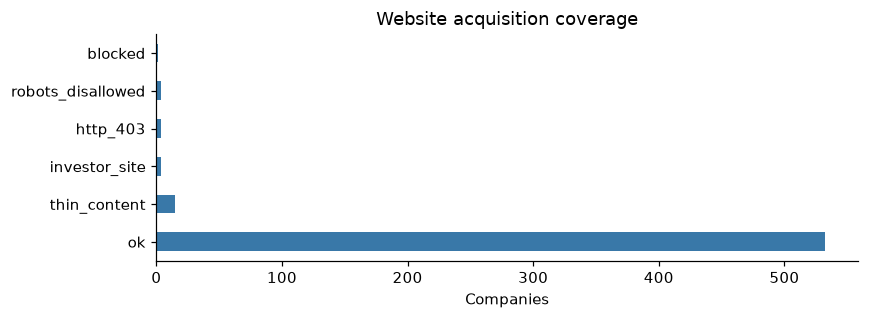

In [4]:
from cleaning_guard import redact_listing_history
website=saved('website_records.json')
scrape_audit=table('website_audit.csv')
guard_rows=[]
for r in companies.itertuples():
    cleaned,removed=redact_listing_history(r.text)
    if removed: guard_rows.append({'ticker':r.target_ciq_ticker,'removed_sentences':len(removed),'example':removed[0]})
display(scrape_audit.groupby(['status','matchable']).size().rename('companies').reset_index())
display(pd.DataFrame(guard_rows))
ax=scrape_audit.status.value_counts().plot.barh(figsize=(8,3),color='#3978a8')
ax.set(xlabel='Companies',ylabel='',title='Website acquisition coverage');plt.tight_layout();plt.show()

In [5]:
def redact_listing_history(text):
    kept=[];removed=[]
    for line in text.splitlines():
        for sentence in re.split(r'(?<=[.!?])\s+',line):
            if LISTING_HISTORY.search(sentence):removed.append(sentence)
            elif sentence.strip():kept.append(sentence)
    return '\n'.join(kept),removed

**Collection entry point.** The exact team collector is embedded, including HTTP, rendered-page and archive fallback implementations. The optional command below refreshes these 19 targets using HTTP only and saves a new capture directory. The frozen report uses the existing captures; refreshing does not silently replace its representations or results.

In [6]:
REFRESH_WEBSITES = False
if REFRESH_WEBSITES:
    import subprocess
    from datetime import datetime, timezone
    refresh_root=DATA/'sources/main'
    input_csv=refresh_root/'refresh_targets.csv'
    text_columns=['IQ_COMPANY_ID','target_company_name','target_ciq_ticker','target_ciq_exchange',
                  'target_ciq_website','target_sic2_code','target_sic3_code','target_sic4_code','target_primary_sic_industry']
    refresh_targets=targets.reindex(columns=text_columns).copy()
    refresh_targets['target_sic2_code']=refresh_targets.target_sic4_code.str[:2]
    refresh_targets['target_sic3_code']=refresh_targets.target_sic4_code.str[:3]
    refresh_targets.to_csv(input_csv,index=False)
    refresh_output=refresh_root/'outputs-local'/('website-refresh-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'))
    subprocess.run([sys.executable,str(refresh_root/'website_scrape/scrape_websites.py'),
                    '--input',str(input_csv),'--out',str(refresh_output),
                    '--methods','html','--max-pages','3'],check=True)
    print('New capture:',refresh_output)
else:
    print('Frozen website captures retained. Collector: sources/main/website_scrape/scrape_websites.py')

Frozen website captures retained. Collector: sources/main/website_scrape/scrape_websites.py


## 3. Text representation and whole-business profiles
**MPNet.** The team encodes 200-word chunks with pinned `all-mpnet-base-v2`, averages normalized chunk vectors and normalizes each company vector. **TF-IDF** is a lexical control (1–2 grams, sublinear term frequency, min_df 2, max_df .95, at most 20,000 features). **LSA** reduces that matrix to 128 components, seed 4511. The latter two are explicit extension specifications; they are not presented as exact copies of Riya's original parameterization. Sentence embedding research motivates testing semantic representations, not treating cosine as economic truth. [Sentence-BERT](https://aclanthology.org/D19-1410/).

The retained legacy representations compare name-masked MPNet, TF-IDF, LSA, Doc2Vec, equal-page pooling, homepage-only pooling and conservative cleaning with the current MPNet text. Five candidates have no valid homepage-only vector; all eight arms therefore use the same 529-company intersection. All 19 targets remain. This comparison is separate from the 535-company selector experiment.

Profiles retain every supported activity and its role, facets and source quotation. Seven new targets were extracted with the existing pinned local 3B model and whole-business prompt; prior profiles and failures were retained. Literal evidence checks do not establish complete company coverage or semantic correctness.

In [7]:
features={name:np.load(DATA/'features'/f'{name}.npy') for name in ['team_mpnet','team_lsa','team_tfidf']}
labels=dict(np.load(DATA/'features/cluster_labels_seed0.npz'))
display(pd.DataFrame([{'representation':k,'rows':v.shape[0],'dimensions':v.shape[1]} for k,v in features.items()]))
display(pd.DataFrame([saved('legacy_extension_manifest.json')]).drop(columns='inputs'))
legacy_comparison=table('legacy_extension_summary.csv')
from notebook_runtime import replay_common_representations,assert_replay_equal
common_companies=pd.read_json(DATA/'common529_companies.json')
common_replayed=replay_common_representations(common_companies,dict(np.load(DATA/'features/common529_triangles.npz')))
print(assert_replay_equal(common_replayed,table('legacy_extension_results.csv')))
display(legacy_comparison[(legacy_comparison.selector=='fixed_cosine_5')&(legacy_comparison.cohort.isin(['original_10','additional_9','combined_19']))][['cohort','representation','scored','median_ape','mean_ape']].round(2))
profile_map=saved('profiles/profiles.json')
display(table('profile_coverage.csv'))
example_id=targets.loc[targets.target_ciq_ticker=='DXPE','IQ_COMPANY_ID'].iloc[0]
display(pd.DataFrame(profile_map[example_id]['known_activities'])[['activity','role','source_id','quote']])

,representation,rows,dimensions
0,team_mpnet,535,768
1,team_lsa,535,128
2,team_tfidf,535,20000


,universe,excluded_from_main535,comparison,representation_missing_companies,amendment
0,529,[IQ1914511668],All representations use identical rows and candidate universe. Legacy text cleaning is an explic...,"[APEI, OGS, PRDO, TDS, WSM]",Home-page-only vectors are missing for five candidates. All eight representations are restricted...


{'rows': 29624, 'configurations': 56, 'identical_within_tolerance': True}


,cohort,representation,scored,median_ape,mean_ape
58,original_10,current_mpnet_common529,10,57.58,105.97
65,original_10,legacy_doc2vec_dbow_cosine,10,56.11,84.52
72,original_10,legacy_mpnet_conservative_cleaning,10,38.05,78.51
79,original_10,legacy_mpnet_home_only,10,57.58,82.54
86,original_10,legacy_mpnet_page_balanced,10,46.90,90.99
93,original_10,legacy_team_lsa,10,20.42,56.27
100,original_10,legacy_team_mpnet_cosine,10,40.50,90.20
107,original_10,legacy_team_tfidf,10,42.55,73.36
114,additional_9,current_mpnet_common529,9,35.74,48.32
121,additional_9,legacy_doc2vec_dbow_cosine,9,39.45,37.09


,ticker,status,activities,eligible,human_reviewed
0,ADUS,model_extracted_unreviewed,5,True,False
1,DOX,truncated_incomplete,0,False,False
2,BV,model_extracted_unreviewed,4,True,False
3,BRO,model_extracted_unreviewed,1,True,False
4,CARG,model_extracted_unreviewed,4,True,False
5,CHGG,model_extracted_unreviewed,2,True,False
6,FIX,model_extracted_unreviewed,4,True,False
7,ROAD,model_extracted_unreviewed,1,True,False
8,DXPE,model_extracted_unreviewed,12,True,False
9,LOPE,model_extracted_unreviewed,3,True,False


,activity,role,source_id,quote
0,Supply Chain Services,service_provider,IQ382071:P1,Decades of supply chain inventory management and consulting experience await you with the Compan...
1,Rotating Equipment Products and Pump Solutions,service_provider,IQ382071:P1,Maintenance repair and operations efficiency\nthe Company has been providing industry-best rotat...
2,Special Fabrications and Custom Parts,service_provider,IQ382071:P1,"Our service centers support rotating equipment, industrial systems, and facility operations. Fro..."
3,Rotating Equipment Repair and Rebuild,service_provider,IQ382071:P1,Rotating equipment repair and rebuild
4,Tool Crib Management,service_provider,IQ382071:P1,Tool Crib Management: How to Control Cutting Tool Inventory
5,Vacuum Pressure Conversion Chart,service_provider,IQ382071:P1,Vacuum Pressure Conversion Chart: Common Units and Formulas
6,Pneumatic Conveying Calculator,service_provider,IQ382071:P1,Pneumatic Conveying Calculator: How to Estimate Blower CFM and Pressure Requirements
7,Industrial Operations Guide,service_provider,IQ382071:P1,A Practical Guide for Industrial Operations
8,Rotating Equipment Bearings & Power Transmission Metal Working Safety Industrial Supplies,distributor,IQ382071:P2,Products - the Company\nRotating Equipment Bearings & Power Transmission Metal Working Safety In...
9,Quality Products From Top-Rated Brands,distributor,IQ382071:P2,Quality Products From Top-Rated Brands the Company is a thriving global distributor of products ...


**Representation findings.** With five peers and the common 529-company pool, LSA has median/mean APE of 29.13%/46.06% on the 19 targets, versus 37.32%/78.66% for current MPNet. This is a promising development-sample result, not evidence that LSA identifies better businesses: the same companies have been used repeatedly, and independent relevance labels are absent. The table separates the original ten from the additional nine.

**Activity comparisons.** An equal-weight activity centroid provides a pooling control. Balanced optimal transport conserves all activity mass; unbalanced transport allows unmatched mass, with penalties 0.25, 1 and 4. Costs are 1 − activity cosine. These are textual activity weights, not revenue shares. A broad or missing activity must not be silently replaced by a favorable business line. The new run uses the original 183-company profile pool plus seven additions, with a dense control on the same profile-eligible pool. DOX remains an extraction failure. These results must not be compared directly with a different candidate universe.

Sources: [Peyré and Cuturi, Computational Optimal Transport](https://arxiv.org/abs/1803.00567); [Chizat et al., Scaling Algorithms for Unbalanced Optimal Transport](https://arxiv.org/abs/1607.05816). The parameter grid is exploratory.

def balanced_ot(cost_matrix, source_mass, target_mass, *, source_ids=None,
                target_ids=None, expected_pot_version=POT_VERSION,
                max_iterations=100000, marginal_tolerance=1e-8):
    """Exact unregularized balanced OT via POT's network-simplex emd solver.

    Equal positive total mass is required; no automatic renormalization. Report
    linear/full objective, plan and both marginal deviations. A solver warning or
    nonconserved marginal makes the result solver_failed with distance=None.
    """
    if max_iterations <= 0 or not np.isfinite(marginal_tolerance) or marginal_tolerance <= 0:
        raise ValueError("iteration limit and marginal tolerance must be positive")
    a, b, costs, result = _transport_inputs(cost_matrix, source_mass, target_mass, source_ids, target_ids)
    result.update(method="balanced_ot", direction="lower", distance=None)
    if result["status"] != "ready":
        return result
    if not np.isclose(a.sum(), b.sum(), rtol=1e-12, atol=1e-12):
        return {**result, "status": "unavailable", "reason": "unequal_total_mass"}
    ot, info = _pot(expected_pot_version)
    result.update(info)
    if ot is None:
        return result
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        plan, log = ot.emd(a, b, costs, numItermax=max_iterations, log=True,
                           numThreads=1, check_marginals=True)
    notices = [str(item.message) for item in caught]
    if not np.isfinite(plan).all() or (plan < -marginal_tolerance).any():
        return {**result, "status": "solver_failed", "reason": "invalid_plan", "warnings": notices}
    diagnostics = _plan_diagnostics(plan, a, b, costs)
    good = (log.get("result_code") == 1 and not log.get("warning") and
            max(diagnostics["source_l1_deviation"], diagnostics["target_l1_deviation"]) <= marginal_tolerance)
    return {**result, **diagnostics, "status": "ok" if good else "solver_failed",
            "distance": diagnostics["linear_cost"] if good else None,
            "full_objective": diagnostics["linear_cost"],
            "objective_definition": "sum(plan * ground_cost), exact balanced marginals",
            "solver_result_code": log.get("result_code"),
            "solver_warning": log.get("warning"), "warnings": notices,
            "max_iterations": max_iterations, "marginal_tolerance": marginal_tolerance}

def unbalanced_ot(cost_matrix, source_mass, target_mass, *, reg, reg_m,
                  source_ids=None, target_ids=None, expected_pot_version=POT_VERSION,
                  max_iterations=10000, tolerance=1e-9):
    """Entropic UOT; explicit KL regularization and independently audited objective.

    Uses reg_type='kl', reference outer(a,b), and finite positive reg_m (scalar
    or source/target pair). Full objective is linear cost + reg*KL(plan,a*b)
    + rho_source*KL(row_sum,a) + rho_target*KL(col_sum,b), with generalized KL.
    POT's library_reported_total_cost is retained separately: its KL convention
    may omit mass correction. Scores across different regularizers/mass policies
    are not automatically comparable. Nonconvergence -> distance=None.
    """
    rho = np.asarray(reg_m, dtype=float).reshape(-1)
    if rho.size == 1:
        rho = np.repeat(rho, 2)
    if rho.size != 2 or not np.isfinite(rho).all() or (rho <= 0).any():
        raise ValueError("reg_m must be one or two finite positive penalties")
    if not np.isfinite(reg) or reg <= 0 or max_iterations <= 0 or not np.isfinite(tolerance) or tolerance <= 0:
        raise ValueError("reg, iteration limit and tolerance must be positive")
    a, b, costs, result = _transport_inputs(cost_matrix, source_mass, target_mass, source_ids, target_ids)
    result.update(method="unbalanced_ot", direction="lower", distance=None,
                  reg=float(reg), reg_m=rho.tolist(), reg_type=UOT_REG_TYPE,
                  reference_measure="outer(source_mass, target_mass)",
                  kl_convention="sum(p*log(p/q)-p+q)")
    if result["status"] != "ready":
        return result
    ot, info = _pot(expected_pot_version)
    result.update(info)
    if ot is None:
        return result
    # Zero-mass support is impossible under finite KL; solve only positive cells.
    ai, bi = a > 0, b > 0
    active_a, active_b = a[ai], b[bi]
    reference = np.outer(active_a, active_b)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        active_plan, log = ot.unbalanced.sinkhorn_unbalanced(
            active_a, active_b, costs[np.ix_(ai, bi)], reg=float(reg),
            reg_m=tuple(rho), method="sinkhorn", reg_type=UOT_REG_TYPE,
            c=reference, numItermax=max_iterations, stopThr=tolerance, log=True)
    notices = [str(item.message) for item in caught]
    if not np.isfinite(active_plan).all() or (active_plan < 0).any():
        return {**result, "status": "solver_failed", "reason": "invalid_plan", "warnings": notices}
    plan = np.zeros_like(costs)
    plan[np.ix_(ai, bi)] = active_plan
    diagnostics = _plan_diagnostics(plan, a, b, costs)
    terms = {"linear_cost": diagnostics["linear_cost"],
             "plan_kl_penalty": float(reg * generalized_kl(plan, np.outer(a, b))),
             "source_kl_penalty": float(rho[0] * generalized_kl(plan.sum(axis=1), a)),
             "target_kl_penalty": float(rho[1] * generalized_kl(plan.sum(axis=0), b))}
    objective = sum(terms.values())
    errors = log.get("err", [])
    converged = bool(errors and np.isfinite(errors[-1]) and errors[-1] < tolerance and not notices)
    return {**result, **diagnostics, "status": "ok" if converged else "solver_failed",
            "distance": float(objective) if converged else None,
            "full_objective": float(objective), "objective_terms": terms,
            "library_reported_total_cost": _safe(log.get("total_cost", np.nan)),
            "solver_method": "sinkhorn", "converged": converged,
            "final_solver_error": _safe(errors[-1]) if errors else None,
            "error_history_length": len(errors), "warnings": notices,
            "max_iterations": max_iterations, "tolerance": tolerance}

342 profile-based estimates reproduced from saved transport/centroid scores.


count  median   mean
method                           k                       
balanced_ot                      3      18   44.62  65.19
                                 5      18   46.66  68.30
                                 10     18   42.63  72.81
dense_same_profile_eligible_pool 3      18   49.87  78.26
                                 5      18   44.83  74.43
                                 10     18   45.57  66.40
profile_centroid                 3      18   42.97  64.88
                                 5      18   52.17  85.40
                                 10     18   49.59  72.35
uot_rho025                       3      18   44.62  65.67
                                 5      18   42.13  77.70
                                 10     18   42.63  70.94
uot_rho1                         3      18   44.62  65.67
                                 5      18   42.13  78.17
                                 10     18   42.63  74.92
uot_rho4                         3      18   44.62  65.67
                                 5      18   44.54  78.63
                                 10     18   42.63  72.95

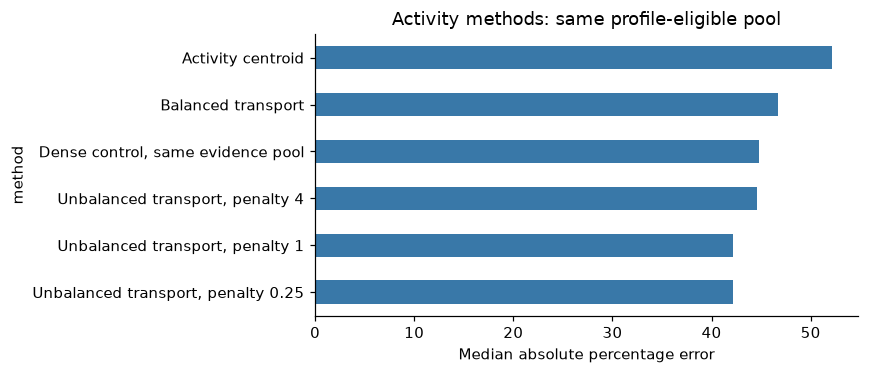

In [8]:
from modular_validation.numeric import balanced_ot,unbalanced_ot
display(Code(inspect.getsource(balanced_ot),language='python'))
display(Code(inspect.getsource(unbalanced_ot),language='python'))
profile_results=table('profile_results.csv')
from notebook_runtime import replay_profile_estimates
profile_replayed=replay_profile_estimates(table('profile_scores.csv'),profile_results,companies)
print(len(profile_replayed),'profile-based estimates reproduced from saved transport/centroid scores.')
display(profile_results.groupby(['method','k']).ape.agg(['count','median','mean']).round(2))
labels_profile={'dense_same_profile_eligible_pool':'Dense control, same evidence pool','profile_centroid':'Activity centroid','balanced_ot':'Balanced transport','uot_rho025':'Unbalanced transport, penalty 0.25','uot_rho1':'Unbalanced transport, penalty 1','uot_rho4':'Unbalanced transport, penalty 4'}
profile_results.query('k==5').groupby('method').ape.median().rename(index=labels_profile).sort_values().plot.barh(figsize=(8,3.5),color='#3978a8')
plt.xlabel('Median absolute percentage error');plt.title('Activity methods: same profile-eligible pool');plt.tight_layout();plt.show()

**Profile findings.** At five peers, unbalanced transport with penalty 0.25 reduces median APE from the matched dense control's 44.83% to 42.13%, while mean APE increases from 74.43% to 77.70%. Balanced transport gives 46.66%/68.30%. These different error tradeoffs do not support a single winner. All comparisons use the same 18 profile-eligible targets; DOX abstains.

## 4. Peer selection
The following adapters implement Michael's three method families, including the cluster route and equal-count controls. Every primary arm uses the same 535 companies and representation rows; no target selects itself. Numerical arrays and cluster labels are embedded, so replay does not introduce a new UMAP draw. The original team notebooks remain the source of the selection specifications.

In [9]:
from peer_methods import *
from notebook_runtime import replay_matching,assert_replay_equal
recomputed,summary=replay_matching(companies,features,labels,design)
print(assert_replay_equal(recomputed,table('valuation_results.csv')))
paired=table('paired_comparisons.csv')
def method_results(selector):
    return summary[(summary.representation=='team_mpnet')&(summary.selector==selector)&(summary.aggregator=='median')][['cohort','targets','scored','median_ape','mean_ape','p90_ape','spearman','median_peers']].round(2)

{'rows': 71690, 'configurations': 134, 'identical_within_tolerance': True}


### 4.1. Cosine z-score selection
For each target, standardize its cosine scores against every other eligible company, using population standard deviation. Retain z ≥ 2 or 2.5. A zero-variance row abstains. These are the team's heuristic cutoffs, not calibrated relevance probabilities or significance tests.

Sources: [reference 1](https://github.com/Qual2Cast/Qual2Cast/blob/7f1f1fc2ddbed8f172b3c89c262d0e44bdfc81bf/matching/matching_methods.ipynb).

In [10]:
def select_z(S, nearest, level):
    out=[]
    for i,order in enumerate(nearest):
        row=S[i,order]; sd=row.std(ddof=0)
        out.append(order[(row-row.mean())/sd>=level].tolist() if sd>1e-12 else [])
    return out

In [11]:
display(method_results('z2'))

,cohort,targets,scored,median_ape,mean_ape,p90_ape,spearman,median_peers
109,all_eligible,535,535,34.73,49.58,101.05,0.31,17.0
243,original_10,10,10,53.01,98.72,162.57,0.15,17.5
377,additional_9,9,9,42.61,47.26,81.25,-0.32,14.0
511,combined_19,19,19,42.63,74.34,103.54,-0.02,16.0


### 4.2. Mutual nearest neighbors
A peer is retained only when each company is in the other's top k (10 or 20). This caps each company's use at k targets. It addresses hub concentration; it does not prove that hubs are economically wrong or that reciprocal peers are correct.

Sources: [reference 1](https://jmlr.org/papers/v11/radovanovic10a.html).

In [12]:
def select_mutual(nearest,rank,k):
    return [[int(j) for j in row[:k] if rank[j,i]<k] for i,row in enumerate(nearest)]

In [13]:
display(method_results('mutual20'))

,cohort,targets,scored,median_ape,mean_ape,p90_ape,spearman,median_peers
90,all_eligible,535,532,34.70,52.05,105.59,0.21,11.0
224,original_10,10,10,52.27,71.39,143.04,0.52,9.5
358,additional_9,9,9,37.73,37.89,49.15,0.35,13.0
492,combined_19,19,19,38.85,55.52,90.80,0.37,11.0


### 4.3. UMAP and HDBSCAN
Reduce the same MPNet vectors to 10 dimensions with 15 neighbors, min_dist 0 and seed 0; apply HDBSCAN with minimum cluster size 5 and sklearn min_samples 2. Compare leaf→eom→mutual20 and eom→mutual20 fallbacks. Report four additional seeds. Density clusters are not business classifications. Numerical/runtime differences can change UMAP partitions.

Sources: [reference 1](https://arxiv.org/abs/1802.03426); [reference 2](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html).

In [14]:
def umap_clusters(E,seed=0):
    import umap
    from sklearn.cluster import HDBSCAN
    X=umap.UMAP(n_components=10,n_neighbors=15,min_dist=0.,metric='cosine',random_state=seed,n_jobs=1).fit_transform(E)
    labels={level:HDBSCAN(min_cluster_size=5,min_samples=2,cluster_selection_method=level,copy=True,n_jobs=1).fit_predict(X) for level in ['leaf','eom']}
    return X,labels

def select_clusters(nearest,rank,labels,start='eom'):
    mutual=select_mutual(nearest,rank,20); out=[]; sources=[]
    for i,row in enumerate(nearest):
        level=next((l for l in (['leaf','eom'] if start=='leaf' else ['eom']) if labels[l][i]>=0),None)
        out.append([int(j) for j in row if labels[level][j]==labels[level][i]] if level else mutual[i])
        sources.append(level or 'mutual20_fallback')
    return out,sources

In [15]:
display(method_results('cluster_eom'))

,cohort,targets,scored,median_ape,mean_ape,p90_ape,spearman,median_peers
41,all_eligible,535,535,35.85,52.84,115.33,0.21,12.0
175,original_10,10,10,53.66,119.06,174.19,-0.12,13.0
309,additional_9,9,9,40.47,35.57,48.80,0.42,13.0
443,combined_19,19,19,42.33,79.51,88.85,0.05,13.0


### 4.4. Complete-linkage hierarchy
Build a tree on 1 − cosine and select the smallest ancestor containing the target and at least five peers. Complete linkage merges according to maximum between-cluster distance. Group size varies, so compare with the fixed-count version as well.

Sources: [reference 1](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html).

In [16]:
def tree_parts(E,S,kind):
    Z=linkage(E,'ward') if kind=='ward' else linkage(squareform(np.clip(1-S,0,None),checks=False),kind)
    n=len(E); parent=np.full(2*n-1,-1,dtype=int); members=[[i] for i in range(n)]+[None]*(n-1)
    for k,(a,b) in enumerate(Z[:,:2].astype(int)):
        parent[a]=parent[b]=n+k; members[n+k]=members[a]+members[b]
    return Z,members,parent

def select_tree(nearest,members,parent,min_peers=5,exact=False):
    if min_peers>=len(nearest): raise ValueError('Not enough candidates')
    out=[]
    for i,row in enumerate(nearest):
        node=i
        while len(members[node])-1<min_peers: node=parent[node]
        peers=[int(j) for j in row if j in set(members[node])]
        out.append(peers[:min_peers] if exact else peers)
    return out

In [17]:
display(method_results('tree_complete'))

,cohort,targets,scored,median_ape,mean_ape,p90_ape,spearman,median_peers
103,all_eligible,535,535,36.29,49.20,96.34,0.22,7.0
237,original_10,10,10,54.16,63.94,117.12,0.60,6.5
371,additional_9,9,9,37.31,33.73,47.05,0.23,7.0
505,combined_19,19,19,39.52,49.63,88.50,0.34,7.0


### 4.5. Ward hierarchy
Build the variance-minimizing hierarchy on Euclidean distances between unit embedding vectors, then use the same ancestor rule. Passing 1 − cosine directly to Ward would be incorrect. Determinism does not establish economic validity.

Sources: [reference 1](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html).

In [18]:
display(method_results('tree_ward'))

,cohort,targets,scored,median_ape,mean_ape,p90_ape,spearman,median_peers
106,all_eligible,535,535,38.21,52.07,107.33,0.23,7.0
240,original_10,10,10,47.99,68.24,134.75,0.72,6.0
374,additional_9,9,9,37.32,40.90,59.04,0.35,6.0
508,combined_19,19,19,37.32,55.29,86.75,0.46,6.0


### 4.6. Equal peer-count controls
Run k = 3,…,10. Cosine takes the first k; the mutual variant ranks by the worse of the two directional ranks; clusters fill from that order; trees are expanded and truncated by cosine. Fixed worst-rank selection is a modified rank rule, not strict mutual-kNN membership.

Sources: [reference 1](https://github.com/Qual2Cast/Qual2Cast/blob/7f1f1fc2ddbed8f172b3c89c262d0e44bdfc81bf/matching/matching_evaluation.ipynb).

In [19]:
def fixed_mutual(nearest,rank,k):
    worst=np.maximum(rank,rank.T)
    return [row[np.argsort(worst[i,row],kind='stable')][:k].tolist() for i,row in enumerate(nearest)]

def fixed_cluster(nearest,rank,labels,k):
    order=fixed_mutual(nearest,rank,len(nearest)-1); out=[]
    for i,row in enumerate(nearest):
        mates=[int(j) for j in row if labels[i]>=0 and labels[j]==labels[i]]
        out.append((mates+[j for j in order[i] if j not in set(mates)])[:k])
    return out

In [20]:
display(method_results('fixed_cosine_5'))

,cohort,targets,scored,median_ape,mean_ape,p90_ape,spearman,median_peers
56,all_eligible,535,535,35.47,51.71,97.78,0.27,5.0
190,original_10,10,10,57.58,105.97,227.15,0.30,5.0
324,additional_9,9,9,35.74,48.92,97.90,0.00,5.0
458,combined_19,19,19,42.79,78.95,125.19,0.18,5.0


**Findings.** On all 535 companies, z ≥ 2 has median APE 34.73%, compared with 34.62% for no matching. Mutual k=20 gives 34.70% on its 532 scored cases; it must also be judged on the same paired targets. Ward is worse than z ≥ 2 in the paired median-error diagnostic. Other selector differences do not establish a general winner. UMAP stability is reported independently of valuation error.

,representation,selector,max_reuse,abstentions
0,team_mpnet,z2,81,0
1,team_mpnet,z2.5,39,13
2,team_mpnet,mutual10,10,27
3,team_mpnet,mutual20,20,3
20,team_mpnet,tree_complete,22,0
29,team_mpnet,tree_ward,15,0
38,team_mpnet,cluster_leaf,30,0
39,team_mpnet,cluster_eom,33,0
48,team_mpnet,scale_revenue,34,0
49,team_mpnet,scale_revenue_margin,36,0


,median,mean,min
level,,,
eom,0.833,0.671,0.0
leaf,0.545,0.582,0.0


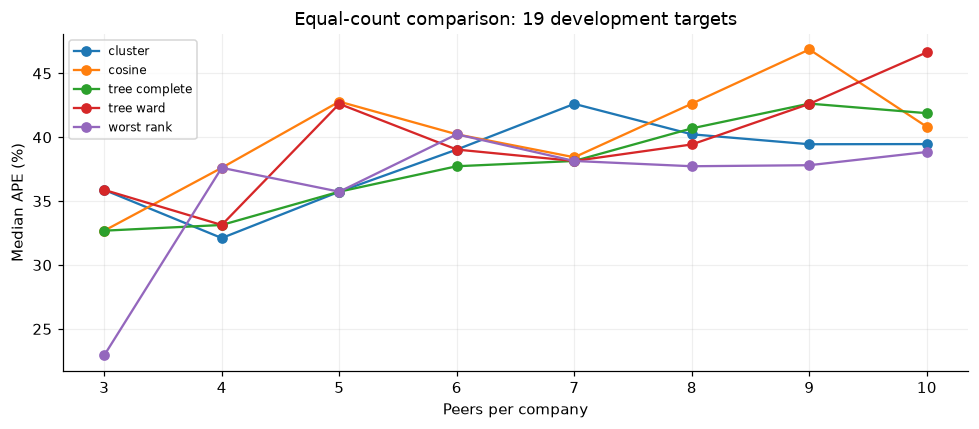

In [21]:
display(table('selector_coverage.csv').query("representation=='team_mpnet' and not selector.str.startswith('fixed_')",engine='python'))
stability=table('cluster_stability.csv')
display(stability.groupby('level').jaccard.agg(['median','mean','min']).round(3))
fixed=summary[(summary.cohort=='combined_19')&(summary.representation=='team_mpnet')&(summary.selector.str.startswith('fixed_'))].copy()
fixed['k']=fixed.selector.str.rsplit('_',n=1).str[-1].astype(int)
fixed['family']=fixed.selector.str.rsplit('_',n=1).str[0]
fig,ax=plt.subplots(figsize=(9,4))
for name,g in fixed.groupby('family'):
    g=g.sort_values('k')
    ax.plot(g.k,g.median_ape,marker='o',label=name.replace('fixed_','').replace('_',' '))
ax.set(xlabel='Peers per company',ylabel='Median APE (%)',title='Equal-count comparison: 19 development targets')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.tight_layout();plt.show()

## 5. Factors and valuation

### Business-first scale reranking
Within the z ≥ 2 text candidate set, rank mean absolute percentile differences in revenue; revenue and EBITDA margin; or revenue, margin and debt/revenue. Take up to five peers. This adapts rank-distance selection to permitted fields. The text screen is only a coarse business filter: qualitative review can still reject the selected peers. EV/EBITDA is never an input.

Sources: [reference 1](https://research.cbs.dk/da/publications/stick-to-the-fundamentals-and-discover-your-peers/); [reference 2](https://onlinelibrary.wiley.com/doi/10.1111/1475-679X.00054).

### Peer-multiple aggregation
Compare the median, nonnegative-cosine weighted median, and a fixed 50/50 blend in log space of the peer median and the leave-one-out global median. Positive finite peer multiples only; no valid peer implies abstention. Weighting and 50/50 shrinkage are exploratory choices, not calibrated optimal weights.

Sources: [reference 1](https://people.stern.nyu.edu/adamodar/pdfiles/papers/valuesurvey.pdf).

In [22]:
def estimate_multiple(values,similarities,global_values,method='median'):
    values=np.asarray(values,float); similarities=np.asarray(similarities,float)
    valid=np.isfinite(values)&(values>0); v=values[valid]
    if not len(v): return np.nan
    if method=='median': return float(np.median(v))
    if method=='cosine_weighted_median':
        w=np.maximum(similarities[valid],0)
        if w.sum()<=0: return np.nan
        order=np.argsort(v,kind='stable'); j=np.searchsorted(np.cumsum(w[order]),w.sum()/2)
        return float(v[order[j]])
    if method=='log_shrink_50':
        g=np.asarray(global_values,float); g=g[np.isfinite(g)&(g>0)]
        return float(np.sqrt(np.median(v)*np.median(g))) if len(g) else np.nan
    raise ValueError(method)

In [23]:
scale_table=summary[(summary.representation=='team_mpnet')&(summary.aggregator=='median')&summary.selector.isin(['z2','scale_revenue','scale_revenue_margin','scale_revenue_margin_leverage','no_matching'])]
display(scale_table[['cohort','selector','scored','median_ape','mean_ape','p90_ape']].round(2))
display(paired[(paired.representation=='team_mpnet')&(paired.aggregator=='median')&(paired.selector=='scale_revenue_margin_leverage')].round(2))
display(summary[(summary.cohort=='combined_19')&(summary.representation=='team_mpnet')&(summary.selector=='z2')][['aggregator','median_ape','mean_ape','p90_ape']].round(2))

,cohort,selector,scored,median_ape,mean_ape,p90_ape
91,all_eligible,no_matching,535,34.62,50.70,105.97
94,all_eligible,scale_revenue,535,35.77,51.32,107.14
97,all_eligible,scale_revenue_margin,535,33.24,51.16,105.70
100,all_eligible,scale_revenue_margin_leverage,535,32.82,48.59,99.84
109,all_eligible,z2,535,34.73,49.58,101.05
225,original_10,no_matching,10,65.77,88.81,120.95
228,original_10,scale_revenue,10,39.98,80.85,146.96
231,original_10,scale_revenue_margin,10,31.92,70.94,106.64
234,original_10,scale_revenue_margin_leverage,10,33.02,81.48,136.83
243,original_10,z2,10,53.01,98.72,162.57


,cohort,representation,selector,aggregator,paired_n,delta,lo,hi
100,all_eligible,team_mpnet,scale_revenue_margin_leverage,median,535,-1.92,-4.80,1.54
234,combined_19,team_mpnet,scale_revenue_margin_leverage,median,19,-18.77,-34.88,6.42
368,original_10,team_mpnet,scale_revenue_margin_leverage,median,10,-19.99,-64.11,6.42
502,additional_9,team_mpnet,scale_revenue_margin_leverage,median,9,-18.76,-33.50,14.26


,aggregator,median_ape,mean_ape,p90_ape
509,cosine_weighted_median,44.80,77.31,111.36
510,log_shrink_50,43.21,68.84,86.25
511,median,42.63,74.34,103.54


**Findings.** Revenue, margin and leverage reranking reduces median APE from 42.63% to 23.86% across the 19 development cases, and from 34.73% to 32.82% across 535. The paired bootstrap intervals include zero. The apparent improvement does not establish business validity: WING–GSHD is a restaurant/insurance mismatch, and FIX–ITT changes a building-services business into a diversified manufacturing peer. The proposed factor stage therefore produces candidates for review, not approved comps. ROIC, retention, maintenance capex and owner earnings remain unavailable; no proxy is silently substituted.

The global-median control's Spearman is suppressed: leave-one-out medians can create a mechanical negative rank relationship. Every error comparison reports coverage. Missing or nonpositive multiples are excluded from aggregation and counted; the snapshot's valuation dates and EBITDA definitions remain unverified.

,selector,scored,median_ape,mean_ape,p90_ape
443,cluster_eom,19,42.33,79.51,88.85
446,cluster_leaf,19,42.33,79.69,88.85
489,mutual10,18,41.60,65.36,105.73
492,mutual20,19,38.85,55.52,90.80
493,no_matching,19,50.99,64.29,75.85
496,scale_revenue,19,42.63,68.18,109.35
499,scale_revenue_margin,19,31.53,56.15,86.97
502,scale_revenue_margin_leverage,19,23.86,57.33,85.03
505,tree_complete,19,39.52,49.63,88.50
508,tree_ward,19,37.32,55.29,86.75


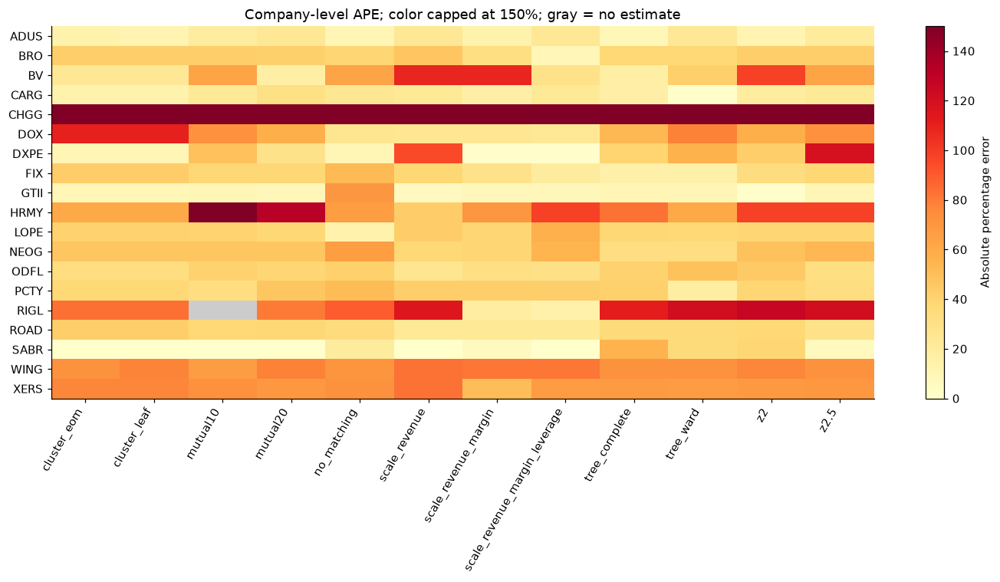

selector,cluster_eom,cluster_leaf,mutual10,mutual20,no_matching,scale_revenue,scale_revenue_margin,scale_revenue_margin_leverage,tree_complete,tree_ward,z2,z2.5
target,,,,,,,,,,,,
ADUS,13.7,11.5,18.8,23.9,9.7,23.9,13.7,23.9,8.4,23.9,11.5,21.0
BRO,42.6,42.6,42.6,41.9,38.8,47.4,32.0,9.1,37.3,37.3,42.6,42.6
BV,23.1,23.1,62.2,16.5,62.9,107.9,107.9,29.1,16.5,42.0,97.9,62.2
CARG,13.0,13.0,22.3,30.8,24.1,22.3,16.1,22.3,16.1,1.7,19.2,22.3
CHGG,752.9,752.9,341.4,242.2,403.6,435.0,435.0,483.9,169.5,258.0,490.9,524.1
DOX,109.9,109.9,73.2,57.7,26.2,24.7,24.7,23.4,52.8,78.2,57.7,73.2
DXPE,9.9,9.9,49.2,28.4,9.8,95.4,0.7,0.7,39.5,55.7,42.6,118.8
FIX,42.9,42.9,37.9,37.9,52.5,37.8,28.8,19.9,15.2,15.2,33.3,37.8
GTII,8.8,8.8,9.9,7.8,70.3,5.4,7.8,7.8,9.9,9.9,1.2,9.9


representation,selector,aggregator,scored,median_ape,mean_ape,p90_ape
team_lsa,fixed_cosine_10,median,19,52.46,70.01,100.02
team_lsa,fixed_cosine_3,median,19,38.14,67.92,100.08
team_lsa,fixed_cosine_4,median,19,37.87,75.50,109.70
team_lsa,fixed_cosine_5,median,19,40.66,69.09,102.53
team_lsa,fixed_cosine_6,median,19,40.59,67.07,95.23
team_lsa,fixed_cosine_7,median,19,43.53,67.93,87.93
team_lsa,fixed_cosine_8,median,19,40.59,69.67,95.23
team_lsa,fixed_cosine_9,median,19,47.05,68.51,102.53
team_lsa,fixed_tree_complete_10,median,19,36.47,49.12,81.24
team_lsa,fixed_tree_complete_3,median,19,42.61,69.08,105.60


In [24]:
core=summary[(summary.cohort=='combined_19')&(summary.representation=='team_mpnet')&(summary.aggregator=='median')&(~summary.selector.str.startswith('fixed_'))]
display(core[['selector','scored','median_ape','mean_ape','p90_ape']].round(2))
heat=recomputed[(recomputed.target.isin(design['targets']))&(recomputed.representation=='team_mpnet')&(recomputed.aggregator=='median')&(recomputed.selector.isin(core.selector))].pivot(index='target',columns='selector',values='ape')
fig,ax=plt.subplots(figsize=(13,7))
heatmap=plt.get_cmap('YlOrRd').copy();heatmap.set_bad('#cccccc')
im=ax.imshow(heat.to_numpy(),aspect='auto',cmap=heatmap,vmin=0,vmax=150)
ax.set_yticks(range(len(heat)),heat.index);ax.set_xticks(range(len(heat.columns)),heat.columns,rotation=60,ha='right')
ax.set_title('Company-level APE; color capped at 150%; gray = no estimate')
fig.colorbar(im,ax=ax,label='Absolute percentage error');plt.tight_layout();plt.show()
display(heat.round(1))
full_grid=summary[summary.cohort=='combined_19'][['representation','selector','aggregator','scored','median_ape','mean_ape','p90_ape']].round(2)
display(HTML('<details><summary>Complete configuration comparison (click to expand)</summary>'+full_grid.to_html(index=False)+'</details>'))

## 6. Business relevance and review
The following cases are provisional interpretations of the saved company pages. They preserve material unmatched activities and distinguish manufacturers, service providers, distributors and marketplaces. They are purposive diagnostics, not independent accuracy labels. A low valuation error cannot override a business mismatch.

In [25]:
case_review=table('qualitative_case_review.csv')
display(case_review[['target','peer','assessment','reason','target_sources','peer_sources']])
human_pairs=table('peer_human_review.csv')
print(len(human_pairs),'deduplicated, shuffled review pairs; zero independent completed labels.')
print(len(table('peer_human_review_full.csv')),'pairs in the union of top-10 results across all current ranking arms.')
display(human_pairs.head(5))

,target,peer,assessment,reason,target_sources,peer_sources
0,BV,TTC,role_mismatch,"BrightView describes landscape design, development and maintenance services. Toro describes equi...",https://www.brightview.com/ | https://www.brightview.com/company/about-brightview | https://www....,https://www.thetorocompany.com/ | https://www.thetorocompany.com/company-information | https://w...
1,BV,FOR,business_mismatch,Forestar describes residential lot development. BrightView provides commercial landscaping throu...,https://www.brightview.com/ | https://www.brightview.com/company/about-brightview | https://www....,https://www.forestar.com/ | https://www.forestar.com/about-us/
2,FIX,SPXC,role_mismatch,"Comfort Systems describes mechanical, electrical, plumbing, modular construction and maintenance...",https://comfortsystemsusa.com/ | https://comfortsystemsusa.com/company-profile | https://comfort...,https://spx.com/ | https://spx.com/our-businesses/hvac/ | https://spx.com/our-company/commitment...
3,FIX,ITT,role_mismatch,"ITT is a diversified component manufacturer across transportation, industrial and energy markets...",https://comfortsystemsusa.com/ | https://comfortsystemsusa.com/company-profile | https://comfort...,https://www.itt.com/ | https://www.itt.com/about/overview | https://www.itt.com/our-solutions/ou...
4,ROAD,STRL,partial_business_overlap,Both have infrastructure exposure. Sterling explicitly includes E-infrastructure and building so...,https://constructionpartners.net/ | https://constructionpartners.net/about-cpi | https://constru...,https://www.strlco.com/ | https://www.strlco.com/who-we-are/about-sterling/ | https://www.strlco...
5,ROAD,DY,business_mismatch,Dycom describes telecommunications and utility contracting. Construction Partners emphasizes asp...,https://constructionpartners.net/ | https://constructionpartners.net/about-cpi | https://constru...,https://dycomind.com/ | https://dycomind.com/what-we-do/ | https://dycomind.com/what-we-do/locat...
6,ODFL,XPO,plausible_overlap_requires_review,Both sites explicitly describe LTL transportation. Old Dominion also lists other freight service...,https://www.odfl.com/ | https://www.odfl.com/us/en/about.html | https://www.odfl.com/us/en/servi...,https://www.xpo.com/ | https://www.xpo.com/about-us/ | https://www.xpo.com/offerings/
7,ODFL,JBHT,partial_business_overlap,"J.B. Hunt describes intermodal, dedicated, over-the-road, last-mile and LTL options. It must ret...",https://www.odfl.com/ | https://www.odfl.com/us/en/about.html | https://www.odfl.com/us/en/servi...,https://www.jbhunt.com/ | https://www.jbhunt.com/our-company | https://www.jbhunt.com/shippers
8,DXPE,DSGR,plausible_overlap_requires_review,Both describe industrial/MRO distribution and supply-chain services. DXP also describes rotating...,https://www.dxpe.com/ | https://www.dxpe.com/product-divisions/ | https://www.dxpe.com/about-us/,https://distributionsolutionsgroup.com/ | https://distributionsolutionsgroup.com/about-us/
9,WING,GSHD,business_mismatch,Wingstop markets restaurant food; Goosehead describes property-and-casualty insurance agency ser...,https://www.wingstop.com/ | https://www.wingstop.com/about-us | https://www.wingstop.com/order,https://www.goosehead.com/ | https://www.goosehead.com/about | https://www.goosehead.com/corpora...


221 deduplicated, shuffled review pairs; zero independent completed labels.
1062 pairs in the union of top-10 results across all current ranking arms.


,pair_id,target,peer,source_urls,target_sources,reviewer,whole_business_relevance_0_to_3,unmatched_activities,role_mismatch,evidence_insufficient,notes
0,PAIR-0001,BV,DFH,https://dreamfindershomes.com/ | https://dreamfindershomes.com/about-us/,https://www.brightview.com/ | https://www.brightview.com/company/about-brightview | https://www....,NaN,NaN,NaN,NaN,NaN,NaN
1,PAIR-0002,CHGG,APEI,https://www.apei.com/overview/default.aspx | https://www.apei.com/about/overview/default.aspx,https://www.chegg.com/ | https://www.chegg.com/about/ | https://www.chegg.com/about/center-for-d...,NaN,NaN,NaN,NaN,NaN,NaN
2,PAIR-0003,FIX,HDSN,https://www.hudsontech.com/ | https://www.hudsontech.com/about-us/ | https://www.hudsontech.com/...,https://comfortsystemsusa.com/ | https://comfortsystemsusa.com/company-profile | https://comfort...,NaN,NaN,NaN,NaN,NaN,NaN
3,PAIR-0004,GTII,TRUL,https://www.trulieve.com/ | https://www.trulieve.com/about | https://www.trulieve.com/dispensaries,https://gtigrows.com/ | https://gtigrows.com/our-story/ | https://gtigrows.com/people/who-we-are/,NaN,NaN,NaN,NaN,NaN,NaN
4,PAIR-0005,NEOG,XERS,https://www.xerispharma.com/ | https://www.xerispharma.com/about-us | https://www.xerispharma.co...,https://www.neogen.com/ | https://www.neogen.com/en/about | https://www.neogen.com/en/usac/solut...,NaN,NaN,NaN,NaN,NaN,NaN


For independent review, two reviewers should score whole-business relevance: **0** = incompatible; **1** = limited activity overlap with material mismatch; **2** = meaningful overlap with stated qualifications; **3** = strong whole-business comparability supported by evidence. Missing evidence is recorded separately rather than scored as incompatibility. Reviewers should not see selector names or valuation outcomes before labeling. Report agreement and disagreements before computing relevance metrics; reconcile afterward, retaining both original labels.

The 221-pair priority sheet covers selected MPNet baselines. The separate full sheet pools the top ten from every current ranking arm, including representation and activity methods. Cross-method relevance comparisons require labels from the same pool; the priority sheet alone cannot fairly evaluate all challengers. Any pooled nDCG must use one shared ideal ranking per target and disclose that the judgments are incomplete outside this pool.

## 7. Growth-signal collection, extraction and temporal features
Growth collection uses raw event text, not the business-description cleaner: the latter deliberately removes dates and hiring/financial language. All 19 targets were attempted sequentially using HTML requests, eight articles and two listing pages per company. No browser automation or bulk model download was needed. The run collected 55 articles; failed requests and zero-article records remain visible.

Three extractors run on the **same captures**: main rules; the unmerged recall branch; and a narrow decimal-window repair on that branch. The recall branch adds actor checks, article/type deduplication, planned/completed status and acquisition, divestiture, funding and guidance events. The decimal repair lets a bounded rule span `$2.2 million` without crossing a sentence boundary. It passes a regression test but adds no event in this live sample. More extracted events do not by themselves imply greater accuracy.

Sources: [team growth pipeline](https://github.com/Qual2Cast/Qual2Cast/tree/7f1f1fc2ddbed8f172b3c89c262d0e44bdfc81bf/growth_signals); [recall branch](https://github.com/Qual2Cast/Qual2Cast/tree/023caabe1b0f0f062a90695dc642306449b3328a/growth_signals); [Doc2EDAG](https://aclanthology.org/D19-1032/) motivates document-level event structure, but that model is not implemented here.

In [26]:
from run_growth import load_arm,decimal_patch,candidate_gate,financial_reporting_page,is_ir
import re
from datetime import datetime,timezone
growth_records={t:saved('growth/'+t+'.json') for t in design['targets']}
from notebook_runtime import replay_growth
growth_events,growth_features=replay_growth(growth_records,saved('growth_run.json')['completed_utc'])
event_keys=['ticker','arm','source_url','event_type','source_text']
event_columns=event_keys+['event_date','public_reporting_page']
pd.testing.assert_frame_equal(growth_events[event_columns].fillna('').sort_values(event_keys).reset_index(drop=True),
    table('growth_events.csv')[event_columns].fillna('').sort_values(event_keys).reset_index(drop=True),check_dtype=False)
feature_keys=['ticker','arm','cutoff']
pd.testing.assert_frame_equal(growth_features.sort_values(feature_keys).reset_index(drop=True),
    table('growth_features.csv').sort_values(feature_keys).reset_index(drop=True),check_dtype=False)
display(growth_events.groupby('arm').size().rename('candidate_records').to_frame())
display(growth_events.query("arm=='decimal_guard_extension'")[['ticker','event_type','event_date','source_url','source_text']])

,candidate_records
arm,
decimal_guard_extension,13
main_rules,3
recall_branch_rules,13


,ticker,event_type,event_date,source_url,source_text
16,DOX,product_launch,2026-08-05,https://www.amdocs.com/press-release/vivo-selects-amdocs-advance-oss-modernization-upgrade-amdoc...,"Introducing CES26, the only Telco-native, Agent-driven suite spanning business, operations and n..."
17,DOX,market_expansion,NaN,https://www.amdocs.com/press-release/veon-and-amdocs-enter-10-year-strategic-agreement-advance-d...,"This agreement also expands Amdocs’ presence in Kazakhstan, Uzbekistan and the wider Eurasia reg..."
18,GTII,market_expansion,2026-10-10,https://investors.gtigrows.com/news-releases/news-release-details/green-thumb-opens-rise-dispens...,"Green Thumb Opens RISE Dispensary in Cape Coral, Expanding Florida Footprint to 25 Locations"
19,GTII,market_expansion,2026-08-10,https://investors.gtigrows.com/news-releases/news-release-details/green-thumb-opens-its-23rd-flo...,"“Opening RISE Dispensary Port Charlotte, our 23rd location in the state, allows us to meet that ..."
20,GTII,product_launch,2026-08-04,https://investors.gtigrows.com/news-releases/news-release-details/green-thumb-industries-reports...,"Launched adult-use sales at RISE Dispensary Paramus in New Jersey on July 13, 2026."
21,BV,hiring,2026-08-04,https://www.brightview.com/resources/press-release/brightview-reports-third-quarter-fiscal-2026-...,"“Our continued focus on prioritizing our front-line employees and customers, expanding our sales..."
22,ROAD,acquisition,2026-08-31,https://ir.constructionpartners.net/news/press-releases/detail/165/construction-partners-inc-com...,"DOTHAN, Ala. , Aug. 31, 2026 /PRNewswire/ -- Construction Partners, Inc. (NASDAQ: ROAD) (""CPI"" o..."
23,ROAD,acquisition,2026-09-21,https://ir.constructionpartners.net/news/press-releases/detail/166/construction-partners-inc-com...,"DOTHAN, Ala. , Sept. 21, 2026 /PRNewswire/ -- Construction Partners, Inc. (NASDAQ: ROAD) (""CPI"" ..."
24,ROAD,market_expansion,2026-09-21,https://ir.constructionpartners.net/news/press-releases/detail/166/construction-partners-inc-com...,This transaction expands CWR's operations in the Florida Panhandle and enhances our ability to s...
25,ROAD,market_expansion,2026-08-07,https://ir.constructionpartners.net/news/press-releases/detail/163/construction-partners-inc-ann...,The acquisition also expands our capabilities in the fast-growing data center construction marke...


In [27]:
def candidate_gate(event,cutoff,strict=True):
    """Eligibility, not factual correctness or estimated forecasting confidence."""
    reasons=[]
    if event.get('via_ir_fallback') or is_ir(event['source_url']): reasons.append('ir_source_excluded_for_private_target')
    if event.get('public_reporting_page'): reasons.append('public_financial_reporting_page')
    d=event.get('event_date')
    if not d: reasons.append('undated')
    elif date.fromisoformat(d)>cutoff.date(): reasons.append('event_after_cutoff')
    if strict and datetime.fromisoformat(event['retrieved_at'].replace('Z','+00:00'))>cutoff:
        reasons.append('evidence_first_observed_after_cutoff')
    return reasons

def financial_reporting_page(page):
    text=' '.join([page.get('source_url',''),page.get('raw_title','')])
    return bool(re.search(r'(?:reports?|announces?)[-\s\w]{0,100}(?:quarter|fiscal|financial|annual)[-\s\w]{0,70}results|earnings[-\s]call',text,re.I))

def decimal_patch(extractor):
    """Let bounded event windows cross decimal points, but not sentence ends."""
    extractor.RULES={key:re.compile(p.pattern.replace('[^.!?]',r'(?:(?<=\d)\.(?=\d)|[^.!?])'),p.flags) for key,p in extractor.RULES.items()}

**Availability and source corrections.** Event-date-only filtering is insufficient for historical replay when the available text was captured later. This implementation additionally requires observed availability by the cutoff, unless an independently retained historical source proves earlier availability. It excludes IR hosts, explicitly flagged IR fallback articles and financial-reporting pages from the private-target arm. The financial-reporting classifier also checks pages on the main corporate domain. These are conservative source gates, not proof that all remaining text is the article's own event.

Zero means no eligible extracted event in the selected observed articles. Null means unavailable evidence. Neither means zero growth. The inherited confidence 0.80 is constant and uncalibrated; it is not an 80% probability of correctness. Publication date is an announcement proxy, not necessarily the event's effective date. Repeated announcements across different URLs still require semantic deduplication and reviewer confirmation.

,ticker,cutoff,collection_status,articles,private_source_articles_observed,team_365d_count,strict_365d_article_type_count,coverage
76,PCTY,2026-10-19,homepage_failed,0,0,NaN,NaN,unavailable
77,PCTY,2026-10-01,homepage_failed,0,0,NaN,NaN,unavailable
78,CHGG,2026-10-19,partial,2,2,NaN,0.0,selected_articles_only
79,CHGG,2026-10-01,partial,2,0,NaN,NaN,unavailable
80,SABR,2026-10-19,ok,0,0,NaN,NaN,unavailable
81,SABR,2026-10-01,ok,0,0,NaN,NaN,unavailable
82,DOX,2026-10-19,partial,5,5,1.0,1.0,selected_articles_only
83,DOX,2026-10-01,partial,5,0,1.0,NaN,unavailable
84,CARG,2026-10-19,homepage_failed,0,0,NaN,NaN,unavailable
85,CARG,2026-10-01,homepage_failed,0,0,NaN,NaN,unavailable


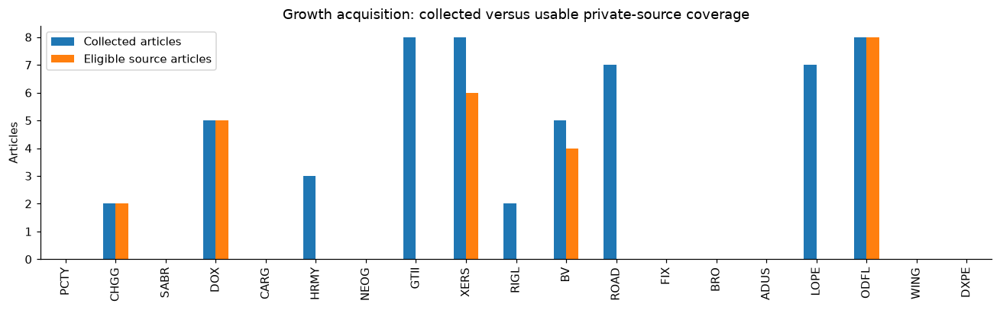

Human event review rows: 68


In [28]:
display(growth_features.query("arm=='decimal_guard_extension'")[['ticker','cutoff','collection_status','articles','private_source_articles_observed','team_365d_count','strict_365d_article_type_count','coverage']])
current=growth_features[(growth_features.arm=='decimal_guard_extension')&(growth_features.cutoff=='2026-10-19')]
ax=current.set_index('ticker')[['articles','private_source_articles_observed']].rename(columns={'articles':'Collected articles','private_source_articles_observed':'Eligible source articles'}).plot.bar(figsize=(12,3.8))
ax.set(ylabel='Articles',xlabel='',title='Growth acquisition: collected versus usable private-source coverage')
plt.tight_layout();plt.show()
print('Human event review rows:',len(table('growth_human_review.csv')))

**Evidence review.** The sole current source-eligible candidate after the strict gates is a CES26 launch sentence inside a DOX article whose title concerns Vivo's OSS upgrade. That mismatch needs article-body attribution review; eligibility alone does not validate it. Consequently no automatically approved growth signal or predictive performance is claimed. The team-reported recall-branch held-out results were approximately 60% precision and 32–39% recall; their uncommitted labels are not embedded or independently reproduced here. Our own new captures require fresh labels, including extractor abstentions, before precision and recall can be reported.

## 8. Revenue outcomes and growth modeling
The team's exact-year outcome builder computes one-, two- and three-year revenue growth from a separate annual revenue panel. The current 560-company snapshot has only one revenue observation per company. Current website captures cannot supply historical predictor vintages.

The executable interface below provides ridge and shallow gradient-boosting alternatives, compares a training-period median baseline, fits preprocessing on training rows, and requires labels to be available by the fitting date. Later observations form the test period. Hyperparameters must be chosen inside earlier temporal folds; a separate later calibration period is required for prediction intervals. The sample-size guard is an engineering minimum, not a claim of statistical sufficiency.

Sources: [scikit-learn temporal validation](https://scikit-learn.org/stable/modules/cross_validation.html); [SEC company-facts API](https://www.sec.gov/search-filings/edgar-application-programming-interfaces) is a potential outcome source, not an input to the private target's text model. No SEC historical panel was acquired in this run.

In [29]:
def evaluate_growth_panel(panel,feature_columns,fit_at,test_from,model_name='ridge'):
    """Train only on labels observable by fit_at; hold out later feature vintages.

    Required long-form rows: company_id, cutoff, label_available_at, growth_3y,
    plus feature columns. Call separately for each rolling origin. Inputs must
    already pass the source-availability gate. No scale or price output is
    inferred from a missing record.
    """
    required={'company_id','cutoff','label_available_at','growth_3y',*feature_columns}
    if panel is None or len(panel)==0:
        return {'status':'not_fitted_missing_historical_panel','predictions':None}
    if not required<=set(panel):raise ValueError('Missing panel columns: '+str(required-set(panel)))
    if panel.duplicated(['company_id','cutoff']).any():raise ValueError('Duplicate company-vintage rows')
    x=panel.copy()
    for col in ['cutoff','label_available_at']:x[col]=pd.to_datetime(x[col],utc=True)
    fit=pd.Timestamp(fit_at);test=pd.Timestamp(test_from)
    if fit.tzinfo is None or test.tzinfo is None or test<=fit:raise ValueError('Test must follow timezone-aware fitting cutoff')
    train=x[(x.cutoff<=fit)&(x.label_available_at<=fit)].dropna(subset=['growth_3y'])
    held=x[x.cutoff>=test].dropna(subset=['growth_3y'])
    if len(train)<30 or len(held)<10:
        return {'status':'not_fitted_insufficient_temporal_rows','train_rows':len(train),'test_rows':len(held),'predictions':None}
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import Ridge
    from sklearn.ensemble import HistGradientBoostingRegressor
    if model_name=='ridge': model=make_pipeline(SimpleImputer(add_indicator=True),StandardScaler(),Ridge(alpha=1.))
    elif model_name=='boosting':model=HistGradientBoostingRegressor(max_iter=100,max_leaf_nodes=7,l2_regularization=1.,random_state=4511)
    else:raise ValueError('Choose ridge or boosting; tune only inside earlier temporal folds')
    model.fit(train[feature_columns],train.growth_3y)
    pred=model.predict(held[feature_columns]);truth=held.growth_3y.to_numpy()
    baseline=np.repeat(train.growth_3y.median(),len(held))
    return {'status':'evaluated','train_rows':len(train),'test_rows':len(held),'mae':float(np.mean(abs(pred-truth))),'training_median_baseline_mae':float(np.mean(abs(baseline-truth))),'predictions':held[['company_id','cutoff']].assign(prediction=pred,actual=truth),'prediction_interval':None,'interval_status':'requires_separate_time-ordered_calibration_sample'}

In [30]:
from growth_model import evaluate_growth_panel
display(evaluate_growth_panel(None,['contract_count','launch_count'],'2022-12-31T00:00:00Z','2023-01-01T00:00:00Z'))
schema,_,_=load_arm('recall')
outcome_source=WORK/'outputs-local/integration-19/sources/recall/growth_signals/build_outcomes.py'
print('Exact-year outcome implementation:',outcome_source.name)
# Inspect the complete implementation when supplying the annual panel:
# display(source('outputs-local/integration-19/sources/recall/growth_signals/build_outcomes.py'))

{'status': 'not_fitted_missing_historical_panel', 'predictions': None}

Exact-year outcome implementation: build_outcomes.py


In [31]:
from run_growth import module
outcomes=module(outcome_source,'revenue_outcomes')
display(Code(inspect.getsource(outcomes.build_revenue_outcomes),language='python'))
# With a real annual panel: outcomes.build_revenue_outcomes(records, cutoff_fiscal_year=2022)

def build_revenue_outcomes(records: list[dict], cutoff_fiscal_year: int) -> list[dict]:
    """Return exact 1-3 year outcomes for companies with cutoff-year revenue."""
    by_company: dict[str, dict[int, float]] = defaultdict(dict)
    company_names: dict[str, str] = {}
    for index, raw_record in enumerate(records, start=1):
        record = _normalize_record(raw_record, f"record {index}")
        company_id = record["IQ_COMPANY_ID"]
        company_name = record["company_name"]
        fiscal_year = record["fiscal_year"]
        if company_id in company_names and company_names[company_id] != company_name:
            raise ValueError(f"conflicting company names for {company_id}")
        company_names[company_id] = company_name
        if fiscal_year in by_company[company_id]:
            raise ValueError(f"duplicate company-year for {company_id}, {fiscal_year}")
        by_company[company_id][fiscal_year] = record["revenue"]

    rows = []
    for company_id in sorted(by_company):
        revenues = by_company[company_id]
        if cutoff_fiscal_year not in revenues:
            continue
        baseline = revenues[cutoff_fiscal_year]
        if baseline <= 0:
            raise ValueError(f"cutoff revenue must be positive for {company_id}")
        row = {
            "IQ_COMPANY_ID": company_id,
            "company_name": company_names[company_id],
            "cutoff_fiscal_year": cutoff_fiscal_year,
            "revenue_at_cutoff": baseline,
        }
        available = 0
        for years in HORIZONS:
            future = revenues.get(cutoff_fiscal_year + years)
            if future is None:
                row[f"revenue_growth_{years}y"] = ""
                row[f"revenue_cagr_{years}y"] = ""
                continue
            row[f"revenue_growth_{years}y"] = future / baseline - 1
            row[f"revenue_cagr_{years}y"] = (future / baseline) ** (1 / years) - 1
            available += 1
        row["outcome_years_available"] = available
        rows.append(row)
    return rows

## 9. Earlier methods and findings retained
The following ledger preserves each earlier method's mechanism, reference and finding. Those observations belong to the frozen original ten-company experiment (usually nine non-PCTY comparison cases, or eight profile-eligible cases). They are not relabeled as 19-company results. The embedded legacy source files retain the implementations; current reruns and coverage are reported separately above.

**Balanced activity optimal transport** (`balanced_activity_ot`). Every accepted activity receives uniform mass. Pairwise cost is 1 − activity cosine; exact Earth Mover's Distance is solved with both marginals conserved. Activity mass may split across counterparts; this is not one-to-one assignment. Ranking uses negative transport cost. All activities must be accounted for, even weakly matching ones.

*Original finding:* Median 57.74% equals dense on eight shared cases, with one improvement, five ties and two regressions; mean is 93.14% versus dense 101.47%. Retaining full mass is inspectable, but extracted activities and equal textual weights are not verified economic exposures.

[source 1](https://proceedings.mlr.press/v37/kusnerb15.html). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Corpus-trained PV-DBOW / Doc2Vec** (`doc2vec_dbow_cosine`). The 534-company eligible text corpus trains 300-dimensional document vectors: PV-DBOW (dm=0), 100 epochs, min_count=2, seed=4511, one worker. The resulting vectors are normalized and ranked by cosine. No relevance or valuation labels train these vectors; corpus inclusion is transductive. Our corpus is much smaller than the website study's.

*Original finding:* Median error is 61.03%, above dense, while mean error improves modestly to 88.22%. Four companies improve and five worsen; CHGG reaches 422.21%. A successful larger-corpus paper is a reason to test this representation, not evidence that this small-corpus run should replace MPNet.

[source 1](https://proceedings.mlr.press/v32/le14.html); [source 2](https://facultynew.tuck.dartmouth.edu/uploads/gordonPhillips/publications/BOKN_Journal___INFORMS_MnSc.pdf). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Debt / revenue only** (`financial_debt_revenue_only`). The factors are debt / revenue. Each is converted to its average-tie percentile rank in the original 534-company reference population. Score = negative mean absolute target–candidate percentile difference; all required factors must be observed. Tests leverage relative to sales, without treating it as total business risk. The paper's ROE, market capitalization, forecast growth and EBIT measures are not silently replaced: this is a declared SARD-inspired adaptation.

*Original finding:* Median/mean 74.34%/115.61% worsen. The ratio alone is not a satisfactory peer-selection criterion.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**Margin + debt / revenue** (`financial_margin_debt_revenue`). The factors are EBITDA / revenue and debt / revenue. Each is converted to its average-tie percentile rank in the original 534-company reference population. Score = negative mean absolute target–candidate percentile difference; all required factors must be observed. Compares profitability and leverage, omitting absolute company scale. The paper's ROE, market capitalization, forecast growth and EBIT measures are not silently replaced: this is a declared SARD-inspired adaptation.

*Original finding:* Median/mean 112.12%/137.58% are poor despite four improved cases. More than one financial ratio is not sufficient evidence of comparability.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**EBITDA margin only** (`financial_margin_only`). The factors are EBITDA / revenue. Each is converted to its average-tie percentile rank in the original 534-company reference population. Score = negative mean absolute target–candidate percentile difference; all required factors must be observed. Tests operating-profitability comparability without scale or capital-structure descriptors. The paper's ROE, market capitalization, forecast growth and EBIT measures are not silently replaced: this is a declared SARD-inspired adaptation.

*Original finding:* Median/mean 62.23%/119.23% both worsen; a similar margin cannot identify the same business.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**Revenue + margin + debt / revenue** (`financial_rank_adapted`). The factors are revenue, EBITDA / revenue and debt / revenue. Each is converted to its average-tie percentile rank in the original 534-company reference population. Score = negative mean absolute target–candidate percentile difference; all required factors must be observed. The main financial arm adds all three available descriptors, without a cosine shortlist. The paper's ROE, market capitalization, forecast growth and EBIT measures are not silently replaced: this is a declared SARD-inspired adaptation.

*Original finding:* Median/mean 68.61%/101.80% exceed dense. All five unrestricted software top-one financial peers lacked a whole-business rationale in the AI source audit; GTII–TRUL is a counterexample to declaring every financial match wrong.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Revenue + debt / revenue** (`financial_size_debt_revenue`). The factors are revenue and debt / revenue. Each is converted to its average-tie percentile rank in the original 534-company reference population. Score = negative mean absolute target–candidate percentile difference; all required factors must be observed. Adds leverage to scale while leaving operating margin out. The paper's ROE, market capitalization, forecast growth and EBIT measures are not silently replaced: this is a declared SARD-inspired adaptation.

*Original finding:* Five cases improve but median/mean 74.92%/103.38% worsen. A majority win count can conflict with aggregate loss when regressions are large.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**Revenue + margin** (`financial_size_margin`). The factors are revenue and EBITDA / revenue. Each is converted to its average-tie percentile rank in the original 534-company reference population. Score = negative mean absolute target–candidate percentile difference; all required factors must be observed. Adds profitability to scale with equal factor weights. The paper's ROE, market capitalization, forecast growth and EBIT measures are not silently replaced: this is a declared SARD-inspired adaptation.

*Original finding:* Median/mean 63.44%/99.07% exceed dense; only three cases improve. The score-consistency calculation below verifies implementation, not relevance.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**Revenue + margin + debt / EBITDA** (`financial_size_margin_debt_ebitda`). The factors are revenue, EBITDA / revenue and derived debt / EBITDA. Each is converted to its average-tie percentile rank in the original 534-company reference population. Score = negative mean absolute target–candidate percentile difference; all required factors must be observed. Replaces debt/revenue by (debt/revenue)/(EBITDA/revenue), requiring positive margin. This transforms existing information; it does not add an independent factor. The paper's ROE, market capitalization, forecast growth and EBIT measures are not silently replaced: this is a declared SARD-inspired adaptation.

*Original finding:* Median stays 68.61%, and mean changes only slightly to 101.48%. The alternative leverage denominator creates little aggregate improvement here; debt ratios are not both counted as independent factors.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**Revenue only** (`financial_size_only`). The factors are revenue. Each is converted to its average-tie percentile rank in the original 534-company reference population. Score = negative mean absolute target–candidate percentile difference; all required factors must be observed. Tests scale alone, while ignoring margin and leverage. The paper's ROE, market capitalization, forecast growth and EBIT measures are not silently replaced: this is a declared SARD-inspired adaptation.

*Original finding:* Median 79.75% is worse; only 2/9 evidence checks pass. Similar size is a weak standalone business match.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**Same-SIC restriction + financial ranks** (`same_sic4_financial`). The same-SIC4 filter is followed by the full revenue/margin/debt-to-revenue distance. This tests the interaction between operating-category restriction and financial comparability, independently of a cosine shortlist. The cited SARD study tested an industry-constrained variant, but our data and ratios differ.

*Original finding:* Median improves to 20.16%, yet mean worsens to 107.48%. CHGG error is 571.25%; its first peer DSP is an advertising platform rather than a learning service. This remains a challenger requiring business review and tail-error reporting.

[source 1](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Same-SIC control with stable-ID ties** (`same_sic4_id_baseline`). Only firms sharing the target's supplied four-digit SIC are retained, in company-ID order. The ID order is arbitrary and has no economic meaning; it makes a deterministic no-within-industry-similarity control. This separates the effect of the industry restriction from a semantic or financial ranking.

*Original finding:* Median 46.95% is close to dense 46.87%, while mean is lower at 70.97%. An arbitrary within-sector order can look competitive on ten development cases, illustrating why snapshot fit alone cannot validate business reasoning.

[source 1](https://doi.org/10.1086/688176); [source 2](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Local LLM: derived unmatched ledger** (`local_llm_derived_activity_ledger`). The amended protocol retains the model, sources, shortlist and token settings, clarifies provisional scope, and derives unmatched IDs deterministically from valid model matches. Malformed matches are rejected; every activity remains accounted for. This amendment was frozen before valuation outcomes, and requires grade ≥2 for proposed peers.

*Original finding:* Usable grades increase to 202/354, but all are grade 0. PCTY–ADP and GTII–TRUL prose acknowledges overlap without valid matching IDs. Better schema compliance has not produced semantic reliability or approved peers. The current grader is unsuitable as an approval gate.

[source 1](https://link.springer.com/article/10.1007/s11142-025-09892-6); [source 2](https://aclanthology.org/2024.findings-naacl.97/). Implementation: `scripts/run_local_peer_judgments_v2.py` (embedded legacy source).

**Local LLM: model-authored activity ledger** (`source_grounded_local_llm_rerank`). Pinned Qwen2.5-3B-Instruct receives paired source-backed dossiers and is asked for matched/unmatched activity IDs, supporting quotes and a 0–3 judgment. Assessment covers a union shortlist; 30 fixed tasks are reversed to examine order effects. The original ordinal output is a diagnostic arm, not automatic approval.

*Original finding:* Only 6/354 forward tasks yield structurally usable grades, all grade 1. No usable grade reaches 2. None of the nine non-PCTY cases has an available primary estimate. The original ordinal control still yields PCTY arithmetic from low-grade peers; that number is diagnostic, not an approved peer valuation. A malformed ledger does not establish business dissimilarity.

[source 1](https://link.springer.com/article/10.1007/s11142-025-09892-6); [source 2](https://aclanthology.org/2024.findings-naacl.97/). Implementation: `scripts/run_local_peer_judgments.py` (embedded legacy source).

**Reciprocal rank fusion** (`mpnet_financial_rrf`). The original dense and financial ordinal ranks are combined as 0.5/(60+rank_dense) + 0.5/(60+rank_financial). Candidates require both component ranks. The constant 60 reduces sensitivity to very top ranks, and equal weights are frozen design choices. Fusion changes information as well as scoring; it is not a pure alternative cosine metric.

*Original finding:* Median rises slightly to 49.56%, but mean falls to 76.65%; four cases improve, one ties and four worsen. It can moderate a financial-only mismatch without guaranteeing a correct business match. It therefore belongs in a separate information arm.

[source 1](https://cormack.uwaterloo.ca/cormacksigir09-rrf.pdf); [source 2](https://research-api.cbs.dk/ws/portalfiles/portal/57344051/thomas_plenborg_et_al_multiv_rdians_ttelse_publishersversion.pdf); [source 3](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Equal standardized-score ensemble** (`team_equal_z_ensemble`). For each target, TF-IDF, LSA and MPNet scores are standardized relative to the candidate reference. Their three z-scores receive equal weights. Standardization puts scores on comparable scales; equal weights are the team's baseline choice, not learned or recommended by the component papers. Correlated components can double-count the same text signal.

*Original finding:* Mean error falls to 65.38%, but median rises to 53.55%; four cases improve, three tie and two worsen. It moderates some large errors while moving the middle of the distribution in the other direction. It remains a fusion control with no consensus guarantee.

[source 1](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting); [source 2](https://scikit-learn.org/stable/modules/decomposition.html#truncated-singular-value-decomposition-and-latent-semantic-analysis); [source 3](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Conservative stored-text cleaning + MPNet** (`mpnet_conservative_cleaning`). This specification restores qualitative scope/history text from stored raw blocks while retaining the protected financial/public-company redactions and name masking. Retained blocks are concatenated under the original chunk-pooling procedure. This is a stored-text ablation, distinct from the separate live-DOM cleaner experiment; no historical HTML is reconstructed.

*Original finding:* Median error stays at 46.87%, mean falls to 83.38%, with two improvements, six ties and one regression. A median alone would hide this change. This remains a diagnostic for evidence loss; two improved outcomes do not identify a universally better cleaner.

[source 1](https://huggingface.co/sentence-transformers/all-mpnet-base-v2); [source 2](https://aclanthology.org/2021.acl-demo.15/). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Homepage-only MPNet** (`mpnet_home_only`). This specification uses only archived home/P1 pages. Their normalized chunk vectors are pooled into page vectors, which receive equal weights. This tests whether short central company descriptions avoid irrelevant subsidiary pages. It also discards product and segment detail. The exact page filter and equal-page weighting are local choices.

*Original finding:* Median/mean error rises to 50.85%/102.36%; only one case improves, five tie and three worsen. Restricting acquisition to the homepage has no broad support in this pilot and risks losing material business lines.

[source 1](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Equal-page MPNet** (`mpnet_page_balanced`). All retained pages are encoded separately. Each page's mean chunk vector is normalized before page vectors are averaged with equal weights. A long page no longer outweighs a short page merely because it has more chunks. Conversely, a small incidental page receives the same page weight as a core product page; this is not revenue weighting.

*Original finding:* Median/mean error is 56.46%/101.36%. Two cases improve, four tie and three worsen. Equalizing page weight does not by itself improve the result; page importance needs source-based evaluation rather than a blanket assumption.

[source 1](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Same-SIC restriction + MPNet** (`same_sic4_mpnet`). The same supplied SIC4 eligibility filter is applied, with MPNet cosine ordering within it. This tests an industry constraint while keeping dense scores fixed. SIC is a single-label classification and may exclude valid cross-code peers or retain firms with different operating models.

*Original finding:* Median/mean rise to 68.28%/152.41%, with three improvements and six regressions. Same-industry restriction does not automatically improve either valuation matching or whole-company relevance.

[source 1](https://doi.org/10.1086/688176); [source 2](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**LSA cosine** (`team_lsa`). The team's truncated-SVD representation is applied to the same TF-IDF matrix, followed by cosine comparison. Latent components combine co-occurring terms, so wording differences may matter less; distinct business activities can also collapse into a common topic. This changes representation while preserving a cosine comparison.

*Original finding:* The 18.56% median is promising, but CHGG error rises from 231.13% to 341.42%. CHGG–BLKB illustrates education-related wording with different buyers and workflows. Four improvements, three ties and two regressions do not establish uniform improvement; five of nine evidence checks pass.

[source 1](https://scikit-learn.org/stable/modules/decomposition.html#truncated-singular-value-decomposition-and-latent-semantic-analysis); [source 2](https://doi.org/10.1086/688176). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**MPNet chunk-mean cosine: reference** (`team_mpnet_cosine`). Pinned all-mpnet-base-v2 encodes 200-word chunks. Normalized chunk vectors are averaged within each company and normalized again. Cosine is the dot product of the final unit vectors. Long pages contribute more chunks. The encoder supports semantic similarity, but the company-level pooling is our adaptation and can dilute small activities.

*Original finding:* The reference produces estimates for all nine non-PCTY cases, with median 46.87% and mean 93.98%. Large CHGG, HRMY and RIGL errors make the mean much higher. This is a reproducible starting point, not an approved business-peer ground truth.

[source 1](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**TF-IDF cosine** (`team_tfidf`). Each company is represented by the team's weighted word/phrase counts, with similarity measured between normalized vectors. Rare terms carry more weight; shared common vocabulary contributes less. This is a lexical control: it can distinguish explicit products but misses paraphrases and can reward incidental shared words.

*Original finding:* Its median error rises to 50.98% while its mean falls to 78.27%. Four cases improve and three tie. It remains an interpretable lexical control; neither the average reduction nor shared terminology proves whole-business fit.

[source 1](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting); [source 2](https://doi.org/10.1086/688176). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Unbalanced activity transport, rho=1** (`unbalanced_activity_ot`). Both marginal constraints are relaxed with KL penalties (rho=1) and entropy/KL regularization 0.05. Ranking uses the saved full regularized objective; transported mass and marginal deviations are reported separately. Dropping difficult activity mass has a cost, but can still hide a material business difference. This is not partial transport with a fixed matched fraction.

*Original finding:* Median improves to 47.74% on eight shared cases, but mean rises to 116.53%. Three improve, three tie and two worsen. Lower typical error comes with worse large errors; unmatched activities must remain explicit.

[source 1](https://arxiv.org/abs/1607.05816); [source 2](https://proceedings.mlr.press/v37/kusnerb15.html). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Unbalanced transport, rho=0.25** (`unbalanced_ot_rho_0.25`). The activities, ground cost and entropy regularization remain fixed; the marginal-deviation penalty is reduced to 0.25. This makes dropping or creating mass less costly. It is a frozen sensitivity arm, not a newly tuned best penalty; its raw objective is not directly comparable to objectives at another rho.

*Original finding:* Median falls to 38.57% versus dense 57.74%, yet mean worsens by 12.77 percentage points. CHGG rises to 478.79%. The stronger median result does not justify discarding company activities or choosing rho on this sample.

[source 1](https://arxiv.org/abs/1607.05816); [source 2](https://proceedings.mlr.press/v37/kusnerb15.html). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Unbalanced transport, rho=4** (`unbalanced_ot_rho_4.0`). The marginal-deviation penalty increases to 4 with the remaining settings fixed, encouraging closer mass conservation. This is still regularized unbalanced transport, not exact balanced EMD. Rankings, transported mass and outcomes require separate comparison; a numerical objective change does not imply a peer-set change.

*Original finding:* Its primary aggregate errors match rho=1: median 47.74%, mean 116.53%. Identical summary errors do not prove every score or ranking is identical. This sensitivity arm provides no new aggregate advantage at k=5/median.

[source 1](https://arxiv.org/abs/1607.05816); [source 2](https://proceedings.mlr.press/v37/kusnerb15.html). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**All six business factor groups** (`business_multifacet_equal`). The specification averages product, customer, role, monetization, delivery and stage similarities across jointly known groups. This combines the two preceding arms with equal group weights. Pairs can have different observed group counts; a high score with little coverage must not be treated as complete company similarity.

*Original finding:* The mean becomes 72.28%, performing better than either of the smaller factor groups, and the median becomes 71.53% compared to 57.74% in the dense scenario. Improvement is observed in four scenarios and regression in four cases. Adding descriptors changes the trade-off but does not provide economic optimal weightings.

[source 1](https://insight.factset.com/resources/at-a-glance-factset-rbics-with-tradenames-datafeed); [source 2](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**Product + customer factors** (`business_product_customer`). Across the common candidate pool, product/function and customer/payer groups are compared separately using the mean of their available cosine scores. Every supported activity contributes; activity text supplies a product fallback when no product facet is extracted. This asks whether matching what is sold and who buys it is sufficient.

*Original finding:* Median error worsens to 77.95%, although mean improves to 83.74% on the eight paired cases. Four improve, one ties and three worsen. Broad product/customer language can align unlike purposes; source audits of CARG–BMBL and CHGG–BMBL expose that risk.

[source 1](https://insight.factset.com/resources/at-a-glance-factset-rbics-with-tradenames-datafeed); [source 2](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**Role + monetization + delivery + stage** (`business_role_monetization`). Operating role, revenue model, delivery model and commercialization stage receive equal weights across jointly observed groups. This tests economic mechanism rather than product vocabulary. A marketplace or subscription label can be shared by companies serving entirely different needs; group pooling can also break within-activity associations.

*Original finding:* Median error reaches 82.67%, with four improvements and four regressions on eight cases. Mean improves to 88.47%, but this does not make role/monetization sufficient for business identity. These fields remain useful evidence alongside product purpose, but are insufficient for standalone approval.

[source 1](https://insight.factset.com/resources/at-a-glance-factset-rbics-with-tradenames-datafeed); [source 2](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_factor_ablation.py` (embedded legacy source).

**All-activity centroid cosine** (`profile_activity_centroid`). Every accepted source-supported activity is encoded. Unit activity vectors receive equal weights in the company centroid, which is normalized and compared by cosine. This explicitly changes the unit from webpage chunks to activities, but averaging still loses the association between individual activities.

*Original finding:* On eight paired cases the median is 89.30% versus dense 57.74%; none improves, three tie and five worsen. Explicit activities alone do not solve pooling loss. This failure provides a control for whether transport adds value beyond an activity centroid.

[source 1](https://huggingface.co/sentence-transformers/all-mpnet-base-v2); [source 2](https://insight.factset.com/resources/at-a-glance-factset-rbics-with-tradenames-datafeed). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

**Sector-specific facet comparison** (`sector_activity_profile`). Candidates are restricted to the supplied SIC4 and compared on five sector facets: software function/buyer/role/delivery/revenue, or health product/use-case/customer/stage/role. All observed activities are pooled within each facet; cosine scores are averaged over jointly known facets. Missing facets remain unknown and pairwise coverage is recorded.

*Original finding:* Median error is 81.02% on eight cases versus dense 57.74%; mean also rises slightly. The supplied sectors contain different business models, so five generic facets and an industry filter are insufficient. DOX remains unavailable rather than being replaced.

[source 1](https://insight.factset.com/resources/at-a-glance-factset-rbics-with-tradenames-datafeed); [source 2](https://huggingface.co/sentence-transformers/all-mpnet-base-v2). Implementation: `scripts/run_modular_validation.py` (embedded legacy source).

In [32]:
legacy_methods=pd.read_csv(WORK/'legacy/method_evidence.csv')
legacy_results=pd.read_csv(WORK/'legacy/results/configuration_results.csv')
display(legacy_methods[['method','family','evidence_scope','local_adaptation']])
print('Frozen original configuration rows:',len(legacy_results))
display(legacy_results.head(8))
# Complete data and code remain inspectable inside this single file:
# display(source('legacy/scripts/run_factor_ablation.py'))

,method,family,evidence_scope,local_adaptation
0,balanced_activity_ot,Balanced activity transport,Method transfer from text matching,Transport all extracted activity mass using 1-cosine cost; equal activity weights are our choice.
1,business_multifacet_equal,Whole-business factors,Enterprise taxonomy and model documentation,"Our activity/facet schema, pooling and equal weights; text presence is not revenue exposure."
2,business_product_customer,Whole-business factors,Enterprise taxonomy and model documentation,"Our activity/facet schema, pooling and equal weights; text presence is not revenue exposure."
3,business_role_monetization,Whole-business factors,Enterprise taxonomy and model documentation,"Our activity/facet schema, pooling and equal weights; text presence is not revenue exposure."
4,doc2vec_dbow_cosine,Doc2Vec,Representation method and website-company research,Train on this small supplied corpus; not a replication of the larger website study.
5,financial_debt_revenue_only,Financial rank distance,Company valuation research,"Revenue, EBITDA margin and leverage subsets replace the paper's full factor set; equal weights a..."
6,financial_margin_debt_revenue,Financial rank distance,Company valuation research,"Revenue, EBITDA margin and leverage subsets replace the paper's full factor set; equal weights a..."
7,financial_margin_only,Financial rank distance,Company valuation research,"Revenue, EBITDA margin and leverage subsets replace the paper's full factor set; equal weights a..."
8,financial_rank_adapted,Financial rank distance,Company valuation research,"Revenue, EBITDA margin and leverage subsets replace the paper's full factor set; equal weights a..."
9,financial_size_debt_revenue,Financial rank distance,Company valuation research,"Revenue, EBITDA margin and leverage subsets replace the paper's full factor set; equal weights a..."


Frozen original configuration rows: 279


,configuration_id,method,k,aggregation,acquisition,representation,similarity,factor_family,candidate_policy,information_regime,...,method_equal_error_count_common,evidence_guard_accepted_targets,evidence_guard_rejected_targets,evidence_guard_unknown_targets,strict_indication_available_targets,strict_indication_withheld_targets,missing_exploratory_estimate_targets,evaluation_scope,original_fresh_subset_status,factor_method_details
0,balanced_activity_ot__k3__median,balanced_activity_ot,3,median,frozen_team_website_snapshot,MPNet_supported_activities_uniform_mass,balanced_exact_EMD_1minus_cosine,all_extracted_supported_activities,common_pilot_excluding_self,website_and_local_source_constrained_extraction,...,4,8,1,0,0,9,1,descriptive_undated_snapshot_proxy_no_pvalues_no_model_selection,source_inspected_exploratory_development_not_independent_holdout,NaN
1,balanced_activity_ot__k3__harmonic,balanced_activity_ot,3,harmonic,frozen_team_website_snapshot,MPNet_supported_activities_uniform_mass,balanced_exact_EMD_1minus_cosine,all_extracted_supported_activities,common_pilot_excluding_self,website_and_local_source_constrained_extraction,...,1,8,1,0,0,9,1,descriptive_undated_snapshot_proxy_no_pvalues_no_model_selection,source_inspected_exploratory_development_not_independent_holdout,NaN
2,balanced_activity_ot__k3__weighted,balanced_activity_ot,3,weighted,frozen_team_website_snapshot,MPNet_supported_activities_uniform_mass,balanced_exact_EMD_1minus_cosine,all_extracted_supported_activities,common_pilot_excluding_self,website_and_local_source_constrained_extraction,...,1,8,1,0,0,9,1,descriptive_undated_snapshot_proxy_no_pvalues_no_model_selection,source_inspected_exploratory_development_not_independent_holdout,NaN
3,balanced_activity_ot__k5__median,balanced_activity_ot,5,median,frozen_team_website_snapshot,MPNet_supported_activities_uniform_mass,balanced_exact_EMD_1minus_cosine,all_extracted_supported_activities,common_pilot_excluding_self,website_and_local_source_constrained_extraction,...,5,8,1,0,0,9,1,descriptive_undated_snapshot_proxy_no_pvalues_no_model_selection,source_inspected_exploratory_development_not_independent_holdout,NaN
4,balanced_activity_ot__k5__harmonic,balanced_activity_ot,5,harmonic,frozen_team_website_snapshot,MPNet_supported_activities_uniform_mass,balanced_exact_EMD_1minus_cosine,all_extracted_supported_activities,common_pilot_excluding_self,website_and_local_source_constrained_extraction,...,1,8,1,0,0,9,1,descriptive_undated_snapshot_proxy_no_pvalues_no_model_selection,source_inspected_exploratory_development_not_independent_holdout,NaN
5,balanced_activity_ot__k5__weighted,balanced_activity_ot,5,weighted,frozen_team_website_snapshot,MPNet_supported_activities_uniform_mass,balanced_exact_EMD_1minus_cosine,all_extracted_supported_activities,common_pilot_excluding_self,website_and_local_source_constrained_extraction,...,0,8,1,0,0,9,1,descriptive_undated_snapshot_proxy_no_pvalues_no_model_selection,source_inspected_exploratory_development_not_independent_holdout,NaN
6,balanced_activity_ot__k10__median,balanced_activity_ot,10,median,frozen_team_website_snapshot,MPNet_supported_activities_uniform_mass,balanced_exact_EMD_1minus_cosine,all_extracted_supported_activities,common_pilot_excluding_self,website_and_local_source_constrained_extraction,...,0,8,1,0,0,9,1,descriptive_undated_snapshot_proxy_no_pvalues_no_model_selection,source_inspected_exploratory_development_not_independent_holdout,NaN
7,balanced_activity_ot__k10__harmonic,balanced_activity_ot,10,harmonic,frozen_team_website_snapshot,MPNet_supported_activities_uniform_mass,balanced_exact_EMD_1minus_cosine,all_extracted_supported_activities,common_pilot_excluding_self,website_and_local_source_constrained_extraction,...,0,8,1,0,0,9,1,descriptive_undated_snapshot_proxy_no_pvalues_no_model_selection,source_inspected_exploratory_development_not_independent_holdout,NaN


## 10. Findings, limitations and integration
1. **Peer selection:** mutual rules reduce hub reuse; clustering and trees change the peer set. None is a universally validated replacement for cosine. Fixed-count variants answer a different question from strict threshold or mutual membership.
2. **Representations and factors:** representation changes and financial reranking can improve one error summary while worsening another or selecting an implausible business. All tables retain coverage and company-level errors.
3. **Whole-business scope:** source-linked activity profiles make omitted roles visible, but evidence completeness and extracted facet truth still require review. DOX is retained as a failure. Activity mass is not economic exposure.
4. **Growth signals:** collection, event extraction, source/time gating and feature assembly execute. Source eligibility, event correctness and growth predictiveness are separate requirements. Historical outcomes and predictor vintages still block a defensible forecast.
5. **Evaluation:** repeated method comparisons on the same development companies invite selection bias. Bootstrap intervals are descriptive, are not multiplicity-adjusted and do not account fully for shared-peer/industry dependence. A fresh labeled sample is needed before adoption.

**Integration recommendation.** Retain the team's collectors and baseline methods; add the availability/source gates, explicit abstentions and shared comparison harness. Treat scale reranking and activity methods as reviewable challengers. The immediate team task is to label the supplied peer/event queues and obtain dated financial definitions and historical revenue/evidence panels. No branch is merged and no message is sent by this notebook.

**Data lineage.** Main `7f1f1fc`; growth recall `023caabe`; snapshot SHA-256 `3ab9a43e7426c1f41a77055a6d3ca9553845cb3046a954e28dc5c2a82c934eae`. The exact sources, settings, local outputs and original findings are embedded with hashes. Model weights are excluded.

In [33]:
print('Replay complete. Primary matching rows:',len(recomputed))
print('Targets:',', '.join(design['targets']))
print('Independent human labels: 0; validated growth forecasts: 0.')
print('Available tables:',', '.join(sorted(p.name for p in DATA.glob('*.csv'))))

Replay complete. Primary matching rows: 71690
Targets: PCTY, CHGG, SABR, DOX, CARG, HRMY, NEOG, GTII, XERS, RIGL, BV, ROAD, FIX, BRO, ADUS, LOPE, ODFL, WING, DXPE
Independent human labels: 0; validated growth forecasts: 0.
Available tables: cluster_stability.csv, growth_eligibility.csv, growth_events.csv, growth_extractor_review.csv, growth_features.csv, growth_human_review.csv, legacy_extension_peers.csv, legacy_extension_results.csv, legacy_extension_summary.csv, paired_comparisons.csv, peer_human_review.csv, peer_human_review_full.csv, profile_cache_initial_coverage.csv, profile_coverage.csv, profile_peers.csv, profile_results.csv, profile_scores.csv, qualitative_case_review.csv, selector_coverage.csv, target_peers.csv, valuation_results.csv, valuation_summary.csv, website_audit.csv
